# Лабораторна 3. Токенізація та трансформери

У цій лабораторній роботі ви пройдете шлях від механіки токенізації до практичного використання готових мовних моделей:

- алгоритми токенізації (BPE, WordPiece, Unigram) — натренуєте всі три на власному тексті;
- mini-GPT з нуля — повторите тренування трансформера на своєму датасеті;
- готові моделі для різних NLP-задач — класифікація, генерація, переклад, Q&A та інше через `pipeline()`;
- порівняння кількох моделей на одній задачі;
- творчий застосунок на основі готової моделі.

Демо-ноутбук лекції 4 (`transformers_demo.ipynb`) — основа для секцій 2-3, звертайтесь до нього як до довідника. Він лежить в архіві демо-матеріалів лекції 4 — посилання «Демо-матеріали (zip)» є в картці лекції на головній сторінці курсу. Розділи 1 і 4 спираються на офіційний [Hugging Face LLM Course](https://huggingface.co/learn/llm-course/en/chapter1/1) — читайте відповідні розділи курсу перед виконанням, посилання додані в кожній секції.

**Відтворення:** збережені результати отримані під час початкових запусків у Google Colab. Код упорядковано для послідовного виконання; нові результати можуть відрізнятися. Для повного запуску потрібні інтернет, достатньо RAM/диска та бажано GPU. Google Drive не монтується.

In [ ]:
%pip install -q torch matplotlib numpy pandas datasets tokenizers "transformers==5.18.0" sentencepiece tensorboard evaluate scikit-learn "gradio>=6,<7"

In [ ]:
import os, sys
from pathlib import Path
from IPython.display import display
# Працюємо в окремій папці, без монтування Google Drive.
ROOT = Path.cwd()
LAB_DIR = ROOT if ROOT.name == "lab3" else ROOT / "lab3"
LAB_DIR.mkdir(parents=True, exist_ok=True)


## Матеріали

- [3Blue1Brown — Transformers, the tech behind LLMs](https://www.youtube.com/watch?v=wjZofJX0v4M)
- [3Blue1Brown — Attention in transformers, step-by-step](https://www.youtube.com/watch?v=eMlx5fFNoYc)
- [3Blue1Brown — How might LLMs store facts](https://www.youtube.com/watch?v=9-Jl0dxWQs8)
- [Hugging Face LLM Course — Chapter 1: Transformer Models](https://huggingface.co/learn/llm-course/en/chapter1/1)
- [Hugging Face LLM Course — Chapter 2: Using Transformers](https://huggingface.co/learn/llm-course/en/chapter2/1)
- [Hugging Face LLM Course — Chapter 6: The Tokenizers library](https://huggingface.co/learn/llm-course/en/chapter6/1)

## 0. Опрацюйте демо-ноутбук лекції 4

Прогляньте пояснення і запустіть усі клітинки демо-ноутбука.

Після цього дайте відповідь на запитання нижче.

### 0.1. Теоретичні питання (якщо потрібно дописати якийсь код, то в блоці "Мої відповіді наведіть відповідний код")

1. У розділі 2.1 демо тренер BPE отримує список окремих віршів, а не один склеєний рядок. Що б змінилось (і що б зламалось), якби ми передали один суцільний рядок?
2. З який етапів складається токенізація, поясніть сутність кожного з етапів (див. [туторіал по токенізації](https://huggingface.co/learn/llm-course/en/chapter6/8))
2. Що таке `"<unk>", "<eos>"` в 2.1.?
3. Зменшіть `VOCAB_SIZE` (2.1) удвічі-втричі (наприклад з 16000 до 4000-6000) і перетренуйте BPE-токенізатор на тому самому корпусі. Порівняйте середню кількість токенів на вірш і частку `<unk>` до/після зміни. Поясніть, чому менший словник не підвищує `<unk>`, але впливає на довжину закодованих послідовностей (а отже — і на кількість кроків, які "бачить" модель за той самий `CONTEXT_LEN`).
4. У розділі 2.2 між віршами вставлено токен `<eos>`. Навіщо? Що конкретно піде не так під час тренування mini-GPT, якщо цей роздільник прибрати?
5. Який формат мають і що репрезентують елементи тензорів `train_data` & `val_data` у розділі 2.3?
6. Допишіть в 3.2. `assert` тест, який перевіряє відповідність частин випадкового батчу.
7. У 3.3 `causal_mask` — нижньотрикутна матриця одиниць. Чому саме нижньотрикутна, а не верхньотрикутна? Що б змінилося в поведінці моделі при генерації тексту, якби маски не було?
8. У 3.10 генерація бере чекпоінт із найкращим `val_loss`, а не останній. За яких умов ці два чекпоінти збігаються, а за яких — ні? Подивіться на свою криву навчання (3.9) і скажіть, який випадок у вас.
10. Зменшіть `EVAL_INTERVAL` у 5 разів (наприклад з 250 до 50) і повторно запустіть тренування. Чи стала крива навчання (3.9) помітно гладкішою/інформативнішою? Скільки додаткового часу це коштує (частіші виклики `estimate_loss()` на `EVAL_ITERS` батчах), і чи є сенс робити `EVAL_INTERVAL` ще меншим?
11. У 4.2 той самий промпт дає дуже різний текст при `temperature=0.2` і `temperature=1.4`. Поясніть математично, що робить `temperature` з логітами перед `softmax`, і чому при дуже високій температурі текст стає майже випадковим.
12. За що саме відповідає параметр `top_p`?
13. У 4.2 змініть налаштування `enable_thinking=False` на `True` запустіть повторно клітинку і прокоментуйте зміни у результаті виконання.

### 0.2. Мої відповіді:
1. Якби замість списку окремих віршів ми передали один суцільний рядок у `train_from_iterator()`, він оброблявся б посимвольно. Через це алгоритм BPE не зміг би коректно визначати частоти сусідніх пар символів та об'єднувати їх у більші токени.

    Якщо ж передати суцільний рядок як один елемент списку, навчання було б можливим, але потребувало б більше оперативної пам'яті. У нашому випадку корпус містить 60 886 196 символів, тому обробляти його у вигляді окремих віршів доцільніше. У результаті навчання на списку віршів було отримано словник розміром 16 000 токенів.

2. Токенізація складається з чотирьох основних етапів:

    1. **Нормалізація (Normalization)** — попередня підготовка тексту, яка може включати видалення зайвих пробілів, приведення символів до нижнього регістру та нормалізацію Unicode.
    2. **Попередня токенізація (Pre-tokenization)** — розбиття тексту на менші частини, наприклад слова та розділові знаки.
    3. **Токенізація за допомогою моделі (Model)** — розбиття отриманих частин на токени відповідно до обраного алгоритму (BPE, WordPiece або Unigram) та присвоєння їм числових ідентифікаторів зі словника.
    4. **Постобробка (Post-processing)** — додавання спеціальних токенів, формування маски уваги та ідентифікаторів типів токенів залежно від потреб моделі.

    У демо-ноутбуці використовується попередня токенізація ByteLevel та алгоритм BPE. Окрема нормалізація тексту не налаштована, а спеціальний токен завершення тексту додається вручну під час кодування корпусу.

  3.
      - **`<unk>` (Unknown Token)** — спеціальний токен, який позначає невідомі символи або фрагменти тексту, які токенізатор не може закодувати за допомогою наявного словника.
      - **`<eos>` (End of Sequence)** — спеціальний токен, який позначає кінець текстової послідовності. У нашому випадку він використовується для позначення кінця кожного вірша та відокремлення його від наступного.

      Обидва спеціальні токени додаються до словника під час навчання BPE-токенізатора.

  4. Під час експерименту я зменшила розмір словника BPE з 16 000 до 6 000 токенів та отримала такі результати:

      | Показник | 16 000 токенів | 6 000 токенів |
      |---|---:|---:|
      | Середня кількість токенів на вірш | 1027,13 | 1173,32 |
      | Частка `<unk>` | 0,000000% | 0,000000% |

      При зменшенні розміру словника середня кількість токенів на один вірш збільшилася на 146,19 токена, тобто приблизно на 14,23%. Це пояснюється тим, що менший словник містить менше готових комбінацій символів, тому слова розбиваються на дрібніші частини.

      Частка невідомих токенів в обох випадках залишилася нульовою завдяки використанню ByteLevel та навчанню на тому самому корпусі.

      Отже, більший словник дозволяє компактніше кодувати текст, а менший призводить до збільшення довжини токенізованих послідовностей.

  5. Токен `<eos>` використовується для позначення кінця одного вірша та відокремлення його від наступного.

      Якщо прибрати цей роздільник, останній токен одного вірша буде безпосередньо з'єднаний із першим токеном наступного. Під час навчання mini-GPT сприйматиме їх як один суцільний текст і вивчатиме неправильні зв'язки між окремими творами.

      У результаті модель не зможе коректно розпізнавати завершення віршів, а під час генерації може різко переходити від однієї теми до іншої.

  6. Тензори `train_data` та `val_data` є одновимірними тензорами типу `torch.int64`. Кожен їхній елемент є числовим ідентифікатором (ID) токена зі словника BPE.

      У результаті виконання коду було отримано:

      - `train_data` — 16 579 771 токен для навчання моделі;
      - `val_data` — 1 842 197 токенів для перевірки якості моделі.

      Перші 10 елементів `train_data`: 544, 10109, 567, 6455, 1933, 2642, 339, 1041, 1114, 8902.

      Таким чином, текстовий корпус представлений у числовому форматі, необхідному для подальшого навчання mini-GPT. Приблизно 90% даних використовується для навчання, а 10% — для валідації.

  7. Для перевірки відповідності вхідної послідовності `xb` та цільової послідовності `yb` я додала такий тест:

      ```python
      assert torch.equal(xb[:, 1:], yb[:, :-1]), "Помилка відповідності батчів!"
      ```

      Результат виконання:

      ```text
      Тест пройдено успішно!
      x: [225, 966, 6709, 833, 13, 3388, 6580, 1169, 413, 6212]
      y: [966, 6709, 833, 13, 3388, 6580, 1169, 413, 6212, 13]
      ```

      Тест підтвердив, що цільова послідовність зміщена на один токен відносно вхідної. Це необхідно для навчання mini-GPT, оскільки модель повинна передбачати наступний токен на основі попередніх.

      Таким чином, випадковий батч сформовано правильно.

  8. Матриця `causal_mask` є нижньотрикутною, оскільки кожен токен повинен мати доступ лише до самого себе та попередніх токенів, а не до майбутніх. Верхньотрикутна матриця, навпаки, дозволяла б бачити майбутні токени та обмежувала б доступ до попередніх.

      Якби маски не було, під час навчання модель могла б бачити наступні токени, які вона повинна передбачити. Це призвело б до витоку інформації та оманливо низького значення функції втрат.

     Під час генерації майбутні токени ще невідомі, тому модель не змогла б використовувати ті самі закономірності, що й під час навчання. У результаті якість згенерованого тексту могла б значно погіршитися.

  9. Найкращий та останній чекпоінти збігаються, якщо найменше значення `val_loss` досягається на останній ітерації навчання. Якщо ж модель починає перенавчатися або значення `val_loss` зростає наприкінці навчання, найкращий чекпоінт може бути отриманий на більш ранній ітерації.

      У моєму випадку отримано такі результати:

      - Кількість ітерацій — 8000.
      - Тривалість навчання — 6,7 хв.
      - Початковий `train_loss` — 9,774.
      - Кінцевий `train_loss` — 5,586.
      - Початковий `val_loss` — 9,774.
      - Кінцевий `val_loss` — 5,661.
      - Найкращий чекпоінт — ітерація 7999.

      На графіку видно, що значення `train_loss` та `val_loss` поступово зменшуються, а різниця між ними залишається невеликою. Явних ознак перенавчання не спостерігається.

      Отже, у моєму випадку найкращий та останній чекпоінти збігаються, оскільки найменше значення `val_loss` було отримано на останній ітерації навчання.

  10. Під час експерименту я зменшила значення `EVAL_INTERVAL` у 5 разів — з 250 до 50 ітерацій. Інші параметри навчання залишила незмінними.

      Отримала такі результати:

      | Показник | EVAL_INTERVAL = 250 | EVAL_INTERVAL = 50 |
      |---|---:|---:|
      | Кількість ітерацій | 8000 | 8000 |
      | Тривалість навчання | 6,7 хв | 10,5 хв |
      | Кінцевий train_loss | 5,586 | 5,554 |
      | Кінцевий val_loss | 5,661 | 5,646 |
      | Найкращий чекпоінт | 7999 | 7999 |

      При зменшенні інтервалу оцінювання час навчання збільшився на 3,8 хвилини, тобто приблизно на 56,7%. Це пояснюється додатковими витратами часу на частішу перевірку якості моделі.

      Другий графік є більш деталізованим та містить більше невеликих коливань. Проте загальна тенденція зменшення функції втрат залишилася однаковою.

      Кінцеві значення функції втрат майже не відрізняються. Незначна різниця може бути пов'язана з випадковою ініціалізацією моделі та формуванням батчів.

      Отже, зменшення `EVAL_INTERVAL` дозволяє детальніше відстежувати процес навчання, але збільшує його тривалість і саме по собі не гарантує покращення якості моделі.

  11. Параметр `temperature` регулює випадковість генерації тексту. Перед застосуванням функції `softmax` кожен логіт ділиться на значення температури:

  $$P_i = \frac{e^{z_i/T}}{\sum_j e^{z_j/T}}$$

  
  де $z_i$ — логіт відповідного токена, а $T$ — температура.

  - **T < 1** — збільшується різниця між імовірностями токенів, тому текст стає більш передбачуваним.
  - **T = 1** — початковий розподіл імовірностей не змінюється.
  - **T > 1** — імовірності токенів зближуються, тому генерація стає більш випадковою.

  При дуже високій температурі розподіл імовірностей наближається до рівномірного, через що модель може вибирати навіть малоймовірні токени, а текст поступово втрачає логічність.

  Під час експерименту при температурі 0,2 було отримано більш послідовний текст, а при температурі 1,4 — менш передбачуваний. Однак одночасно змінювався параметр `top_p`, який також впливає на результат генерації.

  12. Параметр `top_p` визначає, з якого набору токенів модель може вибирати наступний токен під час генерації тексту. Алгоритм сортує токени за спаданням імовірності та залишає найменший набір, сумарна ймовірність якого досягає значення `top_p`.

      - `top_p = 0.1` — модель вибирає токени з вузького набору найбільш імовірних варіантів.
      - `top_p = 0.6` — набір можливих токенів розширюється.
      - `top_p = 0.8` — модель має більше варіантів для генерації.
      - `top_p = 1.0` — обмеження за сумарною ймовірністю відсутнє.

      На відміну від `temperature`, яка змінює розподіл імовірностей токенів, `top_p` обмежує набір токенів, доступних для вибору.

      Чим менше значення `top_p`, тим більш передбачуваним є текст, а збільшення цього параметра сприяє різноманітності генерації.

  13. Після зміни параметра `enable_thinking=False` на `enable_thinking=True` поведінка моделі змінилася.

      При вимкненому режимі модель одразу генерувала продовження історії українською мовою. При увімкненому режимі у результатах з'явився тег `<think>`, після якого модель почала аналізувати завдання англійською мовою, розглядати можливі варіанти розвитку сюжету та обмірковувати структуру відповіді.

      У всіх трьох випадках модель не встигла сформувати кінцеву відповідь, оскільки доступний ліміт токенів було витрачено на міркування. Також під час аналізу модель припустилася помилки, переплутавши Житомирську політехніку з Харківською.

      Отже, увімкнення `enable_thinking` дозволяє моделі попередньо аналізувати завдання, але збільшує кількість необхідних токенів і не гарантує правильності відповіді. Для простого продовження історії доцільніше використовувати `enable_thinking=False`.

---
## 1. Свій датасет

Знайдіть **свій** українськомовний текстовий корпус, достатній за обсягом для mini-GPT — наприклад, на [Hugging Face Datasets](https://huggingface.co/datasets?language=language:uk) або на [Kaggle](https://www.kaggle.com/datasets?search=ukrainian). Жанр і епоха — на ваш вибір (новини, художня література, вікіпедія, форуми, судові рішення тощо), головне — одна мова (українська) і достатньо тексту, щоб токенізатор і модель побачили бодай прості закономірності.

⚠️ Якщо датасет великий (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`), інакше отримаєте помилку нестачі пам'яті (out of memory, OOM).

⚠️ Якщо датасет доступний лише через `streaming=True` (наприклад, через розмір) — `load_dataset(..., streaming=True).take(N)` повертає `IterableDataset`, у якого **нема** `.to_pandas()` і `len()`. Спершу матеріалізуйте вибірку в список, а вже потім — у `DataFrame`:
```python
rows = list(streamed_ds)
poems_df = pd.DataFrame(rows)
```

In [2]:
from datasets import load_dataset

dataset = load_dataset(
    "Zarakun/ukrainian_news",
    split="train"
)

news_df = dataset.to_pandas()

print("Кількість новин:", len(news_df))
print("Колонки:", news_df.columns.tolist())
print("\nПриклад тексту:")
print(news_df["text"].iloc[0][:500])

README.md:   0%|          | 0.00/555 [00:00<?, ?B/s]

data/train/train_dataset.parquet: reconstructing file:   0%|          |  0.00B / 3.45MB            

data/train/train_dataset.parquet: downloading bytes:           |  0.00B            

data/test/test_dataset.parquet: reconstructing file:   0%|          |  0.00B /  394kB            

data/test/test_dataset.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/1727 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/192 [00:00<?, ? examples/s]

Кількість новин: 1727
Колонки: ['filename', 'language', 'main_topic', 'other_topic', 'text']

Приклад тексту:
Чверть українських учнів хотіли б виїхати за кордон. У багатьох з них – песимістичні погляди на майбутнє.Про це заявила ексміністерка освіти та науки України Ганна Новосад. Вона при цьому поділилася результатами дослідження, проведеного в українських школах, під назвою "Війна та освіта. 2 роки повномасштабного вторгнення". Скільки учнів хочуть виїхати за кордон. Згідно з результатами, 24% опитаних учнів мають песимістичні погляди на майбутнє, 26% учнів скоріше б хотіли переїхати за кордон (30% з


In [3]:
print("Мови датасету:")
print(news_df["language"].value_counts())

news_df = news_df.dropna(subset=["text"])
news_df = news_df.drop_duplicates(subset=["text"])
news_df = news_df[news_df["text"].str.strip() != ""]

news_texts = news_df["text"].str.strip().tolist()
corpus_text = "\n\n".join(news_texts)

print("\nКількість новин:", len(news_texts))
print("Кількість символів:", len(corpus_text))
print("Кількість слів:", len(corpus_text.split()))
print("Унікальних слів:", len(set(corpus_text.split())))
print("Розмір корпусу (МБ):",
      round(len(corpus_text.encode("utf-8")) / 1024**2, 2))

Мови датасету:
language
ua    1727
Name: count, dtype: int64

Кількість новин: 1640
Кількість символів: 3512704
Кількість слів: 495788
Унікальних слів: 100603
Розмір корпусу (МБ): 6.05


Для виконання лабораторної роботи я обрала датасет [Zarakun/ukrainian_news](https://huggingface.co/datasets/Zarakun/ukrainian_news) з платформи Hugging Face, який містить українськомовні новини різної тематики.

Для формування текстового корпусу використала колонку `text` навчальної вибірки. Перевірила мову текстів, видалила дублікати та порожні записи.

Після підготовки корпусу отримала такі результати:

| Показник | Значення |
|---|---:|
| Початкова кількість новин | 1727 |
| Кількість новин після очищення | 1640 |
| Кількість символів | 3 512 704 |
| Кількість слів | 495 788 |
| Кількість унікальних слів | 100 603 |
| Обсяг корпусу | 6,05 МБ |
| Мова | Українська |
| Жанр | Новини |

Підготовлений текстовий корпус буде використано для навчання та порівняння токенізаторів, а також для навчання власної моделі mini-GPT.

---
## 2. Токенізатори: BPE, WordPiece, Unigram

Демо тренує лише BPE. У цій секції ви натренуєте й порівняєте всі три основні алгоритми токенізації на **своєму** тексті.

Матеріал — офіційний [Hugging Face LLM Course, розділ 6](https://huggingface.co/learn/llm-course/en/chapter6/1). Пройдіть і повторіть на своїх даних:

1. **[6.2. Тренування нового токенізатора на основі старого](https://huggingface.co/learn/llm-course/en/chapter6/2)** — найпростіший шлях: `tokenizer.train_new_from_iterator(...)` на основі архітектури готового токенізатора (наприклад, `Qwen/Qwen2.5-0.5B-Instruct`). Зробіть це як розминку перед ручними варіантами нижче.
2. **[6.5. Алгоритм BPE](https://huggingface.co/learn/llm-course/en/chapter6/5)** — повторіть покрокову реалізацію з туторіалу на своєму тексті, повністю вручну або за допомогою бібліотеки `tokenizers`.
3. **[6.6. Алгоритм WordPiece](https://huggingface.co/learn/llm-course/en/chapter6/6)** — так само.
4. **[6.7. Алгоритм Unigram](https://huggingface.co/learn/llm-course/en/chapter6/7)** — так само.

### 1.1. Порівняння

Для однакового `vocab_size` (візьміть, наприклад, 500 — на невеликому зразку тексту більший словник не встигне показати різницю) порівняйте три токенізатори в невеликій таблиці: розмір словника, кількість токенів на вашому зразку, скільки токенів виходить на кількох обраних словах (частотне й рідкісне — як у лекції). Коротко письмово: який алгоритм дав найкоротші послідовності на вашому тексті і чи це узгоджується з тим, що каже туторіал про природу кожного алгоритму?

In [5]:
from transformers import AutoTokenizer

old_tokenizer = AutoTokenizer.from_pretrained(
    "Qwen/Qwen2.5-0.5B-Instruct"
)

new_tokenizer = old_tokenizer.train_new_from_iterator(
    news_texts,
    vocab_size=500
)

sample = news_texts[0][:250]

print("Розмір старого словника:", len(old_tokenizer))
print("Розмір нового словника:", len(new_tokenizer))

print("\nПочатковий текст:")
print(sample)

print("\nСтарий токенізатор:")
print(old_tokenizer.tokenize(sample))

print("\nНовий токенізатор:")
print(new_tokenizer.tokenize(sample))

print("\nКількість токенів (старий):",
      len(old_tokenizer.tokenize(sample)))

print("Кількість токенів (новий):",
      len(new_tokenizer.tokenize(sample)))

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

Розмір старого словника: 151665
Розмір нового словника: 508

Початковий текст:
Чверть українських учнів хотіли б виїхати за кордон. У багатьох з них – песимістичні погляди на майбутнє.Про це заявила ексміністерка освіти та науки України Ганна Новосад. Вона при цьому поділилася результатами дослідження, проведеного в українських

Старий токенізатор:
['Ð§', 'Ð²ÐµÑĢ', 'ÑĤÑĮ', 'ĠÑĥÐºÑĢÐ°', 'ÑĹ', 'Ð½', 'ÑģÑĮ', 'ÐºÐ¸', 'Ñħ', 'ĠÑĥÑĩ', 'Ð½', 'Ñĸ', 'Ð²', 'ĠÑħÐ¾ÑĤ', 'Ñĸ', 'Ð»Ð¸', 'ĠÐ±', 'ĠÐ²', 'Ð¸', 'ÑĹ', 'Ñħ', 'Ð°ÑĤ', 'Ð¸', 'ĠÐ·Ð°', 'ĠÐºÐ¾ÑĢ', 'Ð´Ð¾Ð½', '.', 'ĠÐ£', 'ĠÐ±', 'Ð°Ð³', 'Ð°ÑĤÑĮ', 'Ð¾', 'Ñħ', 'ĠÐ·', 'ĠÐ½Ð¸Ñħ', 'ĠâĢĵ', 'ĠÐ¿ÐµÑģ', 'Ð¸Ð¼', 'Ñĸ', 'ÑģÑĤ', 'Ð¸Ñĩ', 'Ð½', 'Ñĸ', 'ĠÐ¿', 'Ð¾Ð³', 'Ð»Ñı', 'Ð´Ð¸', 'ĠÐ½Ð°', 'ĠÐ¼', 'Ð°Ð¹', 'Ð±', 'ÑĥÑĤ', 'Ð½', 'ÑĶ', '.', 'ÐŁÑĢÐ¾', 'ĠÑĨ', 'Ðµ', 'ĠÐ·Ð°Ñı', 'Ð²Ð¸', 'Ð»Ð°', 'ĠÐµ', 'ÐºÑģ', 'Ð¼', 'Ñĸ', 'Ð½', 'Ñĸ', 'ÑģÑĤÐµÑĢ', 'ÐºÐ°', 'ĠÐ¾Ñģ', 'Ð²', 'Ñĸ', 'ÑĤÐ¸', 'ĠÑĤ', 'Ð°', 'ĠÐ½Ð°', 'Ñĥ', 'ÐºÐ¸', 'ĠÐ£ÐºÑĢÐ°', 'ÑĹ', 'Ð½Ð¸', 'ĠÐĵ', 'Ð°Ð½', 'Ð½Ð°', 'ĠÐĿ', 'Ð¾Ð

Для експерименту я використала готовий токенізатор Qwen2.5-0.5B-Instruct та перенавчила його на власному корпусі українськомовних новин за допомогою методу `train_new_from_iterator()`.

Отримала такі результати:

| Показник | Початковий токенізатор | Новий токенізатор |
|---|---:|---:|
| Розмір словника | 151 665 | 508 |
| Кількість токенів у тестовому уривку | 119 | 137 |

Хоча при навчанні було задано розмір словника 500, фактичний розмір становить 508 через додаткові спеціальні токени.

Новий токенізатор розбив текст на більшу кількість токенів, оскільки його словник значно менший. Незвичне відображення символів у результатах пояснюється використанням байтового представлення тексту, а не помилкою кодування.

Отже, метод `train_new_from_iterator()` дозволяє адаптувати готовий токенізатор до власного текстового корпусу, зберігаючи його основний алгоритм токенізації.

In [6]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers

VOCAB_SIZE = 500
SPECIAL_TOKENS = ["<unk>", "<eos>"]

bpe_tokenizer = Tokenizer(
    models.BPE(unk_token="<unk>")
)

bpe_tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()

bpe_trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS
)

bpe_tokenizer.train_from_iterator(
    news_texts,
    trainer=bpe_trainer
)

sample = news_texts[0][:250]
words = ["Україна", "освіта", "ексміністерка", "електроенцефалографія"]

encoded = bpe_tokenizer.encode(sample)

print("Розмір словника:", bpe_tokenizer.get_vocab_size())
print("Кількість токенів:", len(encoded.ids))
print("Токени:", encoded.tokens)

print("\nТокенізація окремих слів:")
for word in words:
    tokens = bpe_tokenizer.encode(word).tokens
    print(f"{word}: {tokens} — {len(tokens)} токенів")

Розмір словника: 500
Кількість токенів: 110
Токени: ['Ч', 'вер', 'ть', 'україн', 'сь', 'ких', 'у', 'ч', 'нів', 'хо', 'ті', 'ли', 'б', 'ви', 'їх', 'а', 'ти', 'за', 'ко', 'р', 'до', 'н', '.', 'У', 'бага', 'ть', 'о', 'х', 'з', 'них', '–', 'пе', 'си', 'мі', 'сти', 'ч', 'ні', 'по', 'гля', 'ди', 'на', 'ма', 'й', 'бу', 'т', 'н', 'є', '.', 'П', 'ро', 'це', 'за', 'я', 'ви', 'ла', 'е', 'к', 'с', 'мі', 'ні', 'ст', 'ер', 'ка', 'о', 'сві', 'ти', 'та', 'на', 'у', 'ки', 'Украї', 'ни', 'Г', 'ан', 'на', 'Н', 'о', 'во', 'са', 'д', '.', 'В', 'она', 'при', 'ць', 'ому', 'по', 'ді', 'ли', 'ла', 'ся', 'ре', 'зу', 'ль', 'та', 'та', 'ми', 'до', 'слі', 'д', 'ження', ',', 'про', 'ве', 'де', 'ного', 'в', 'україн', 'сь', 'ких']

Токенізація окремих слів:
Україна: ['Украї', 'на'] — 2 токенів
освіта: ['о', 'сві', 'та'] — 3 токенів
ексміністерка: ['е', 'к', 'с', 'мі', 'ні', 'ст', 'ер', 'ка'] — 8 токенів
електроенцефалографія: ['е', 'ле', 'к', 'т', 'ро', 'ен', 'це', 'ф', 'а', 'ло', 'гра', 'фі', 'я'] — 13 токенів


In [7]:
from tokenizers import decoders

wp_tokenizer = Tokenizer(
    models.WordPiece(unk_token="<unk>")
)

wp_tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
wp_tokenizer.decoder = decoders.WordPiece(prefix="##")

wp_trainer = trainers.WordPieceTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS
)

wp_tokenizer.train_from_iterator(
    news_texts,
    trainer=wp_trainer
)

encoded = wp_tokenizer.encode(sample)

print("Розмір словника:", wp_tokenizer.get_vocab_size())
print("Кількість токенів:", len(encoded.ids))
print("Токени:", encoded.tokens)

print("\nТокенізація окремих слів:")
for word in words:
    tokens = wp_tokenizer.encode(word).tokens
    print(f"{word}: {tokens} — {len(tokens)} токенів")

Розмір словника: 500
Кількість токенів: 140
Токени: ['Ч', '##в', '##ер', '##ть', 'у', '##краї', '##н', '##сь', '##ки', '##х', 'у', '##ч', '##ні', '##в', 'х', '##о', '##ті', '##ли', 'б', 'ви', '##ї', '##х', '##а', '##ти', 'за', 'ко', '##р', '##д', '##о', '##н', '.', 'У', 'б', '##а', '##га', '##ть', '##о', '##х', 'з', 'н', '##и', '##х', '–', 'п', '##е', '##си', '##мі', '##ст', '##и', '##ч', '##ні', 'по', '##г', '##ля', '##ди', 'на', 'ма', '##й', '##б', '##у', '##т', '##н', '##є', '.', 'П', '##ро', 'це', 'за', '##я', '##ви', '##ла', 'е', '##к', '##с', '##мі', '##ні', '##ст', '##ер', '##ка', 'о', '##с', '##ві', '##ти', 'та', 'на', '##у', '##ки', 'У', '##краї', '##ни', 'Г', '##ан', '##на', 'Н', '##ов', '##о', '##с', '##а', '##д', '.', 'В', '##о', '##на', 'при', 'ц', '##ь', '##ому', 'по', '##ді', '##ли', '##ла', '##ся', 'ре', '##з', '##у', '##ль', '##та', '##та', '##ми', 'до', '##с', '##лі', '##д', '##же', '##н', '##ня', ',', 'про', '##в', '##е', '##де', '##но', '##го', 'в', 'у', '##краї', '

In [8]:
unigram_tokenizer = Tokenizer(models.Unigram())

unigram_tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()

unigram_trainer = trainers.UnigramTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=SPECIAL_TOKENS,
    unk_token="<unk>"
)

unigram_tokenizer.train_from_iterator(
    news_texts,
    trainer=unigram_trainer
)

encoded = unigram_tokenizer.encode(sample)

print("Розмір словника:", unigram_tokenizer.get_vocab_size())
print("Кількість токенів:", len(encoded.ids))
print("Токени:", encoded.tokens)

print("\nТокенізація окремих слів:")
for word in words:
    tokens = unigram_tokenizer.encode(word).tokens
    print(f"{word}: {tokens} — {len(tokens)} токенів")

Розмір словника: 500
Кількість токенів: 104
Токени: ['Ч', 'вер', 'ть', 'українськ', 'их', 'у', 'ч', 'ні', 'в', 'х', 'о', 'ті', 'ли', 'б', 'ви', 'їх', 'а', 'ти', 'за', 'кордон', '.', 'У', 'ба', 'г', 'а', 'ть', 'о', 'х', 'з', 'них', '–', 'пе', 'с', 'им', 'і', 'с', 'тичн', 'і', 'по', 'г', 'ля', 'ди', 'на', 'майбутн', 'є', '.', 'П', 'ро', 'це', 'за', 'я', 'ви', 'ла', 'екс', 'мін', 'і', 'с', 'тер', 'ка', 'о', 'світ', 'и', 'та', 'на', 'у', 'ки', 'Україн', 'и', 'Г', 'а', 'н', 'на', 'Н', 'о', 'в', 'о', 'с', 'а', 'д', '.', 'Вон', 'а', 'при', 'ць', 'ому', 'по', 'ді', 'ли', 'ла', 'ся', 'результат', 'ами', 'до', 'слід', 'ження', ',', 'про', 'в', 'е', 'де', 'ного', 'в', 'українськ', 'их']

Токенізація окремих слів:
Україна: ['Україн', 'а'] — 2 токенів
освіта: ['о', 'світ', 'а'] — 3 токенів
ексміністерка: ['екс', 'мін', 'і', 'с', 'тер', 'ка'] — 6 токенів
електроенцефалографія: ['е', 'ле', 'к', 'т', 'ро', 'ен', 'це', 'ф', 'а', 'ло', 'гра', 'фі', 'я'] — 13 токенів


На власному корпусі українськомовних новин я навчила три токенізатори: BPE, WordPiece та Unigram. Для коректного порівняння використала однаковий розмір словника (500 токенів), однаковий корпус та однакові тестові приклади.

**Результати порівняння:**

| Показник | BPE | WordPiece | Unigram |
|---|---:|---:|---:|
| Розмір словника | 500 | 500 | 500 |
| Кількість токенів в уривку | 110 | 140 | 104 |
| Україна | 2 | 3 | 2 |
| освіта | 3 | 4 | 3 |
| ексміністерка | 8 | 8 | 6 |
| електроенцефалографія | 13 | 16 | 13 |

**Особливості алгоритмів:**

- **BPE** — поступово об'єднує найчастіші пари сусідніх символів у більші токени.
- **WordPiece** — формує словник підслів та використовує префікс `##` для позначення продовження слова.
- **Unigram** — використовує ймовірнісну модель для вибору найбільш імовірного варіанта розбиття тексту на токени.

У моєму експерименті найменшу кількість токенів отримано за допомогою Unigram — 104. BPE показав близький результат — 110 токенів, а WordPiece розбив текст на 140 токенів.

Також помітно, що складні та довгі слова всі три алгоритми розбивають на більшу кількість частин.

Отже, серед досліджених прикладів Unigram забезпечив найбільш компактне представлення українськомовного тексту. Проте це не означає, що він завжди буде найефективнішим, оскільки результат залежить від корпусу, розміру словника та особливостей тексту.

---
## 3. mini-GPT на своїх даних

Повторіть підхід із розділів 2-3 демо-ноутбука на своєму датасеті — не копіюйте код один в один: у вашого датасету інша колонка з текстом, інший обсяг, інший жанр/регістр мови — токенізатор і модель побачать зовсім інші закономірності, ніж на поезії з демо.

### 3.1. Корпус і токенізація

1. Завантажте свій датасет і зберіть `corpus_text` з потрібної колонки (демо 1.2).
2. Натренуйте токенізатор на своєму корпусі (демо 2.1). **Якщо ваш датасет великий** (сотні МБ тексту і більше) — кодуйте корпус пачками, як у демо 2.2 (`encode_batch` + конвертація в `numpy.int32`). Не забудьте `<eos>` між документами (демо 2.2).
3. Спліт train/val (демо 2.3).

### 3.2. Модель: щонайменше 2 варіанти

За зразком розділу 3 демо (`AttentionHead`, `MultiHeadAttention`, `TransformerBlock`, `MiniGPT`) — тренуйте щонайменше 2 варіанти, які відрізняються параметрами: інший `VOCAB_SIZE`, інша `CONTEXT_LEN`, інша кількість шарів/голів (`N_LAYERS`/`N_HEADS`), або інший `MAX_ITERS`. Кожен варіант логуйте в TensorBoard в окрему підпапку (як у демо 3.8), з осмисленою назвою.

### 3.3. Генерація і висновки

Для кожного варіанта — генерація на найкращому за `val_loss` чекпоінті (демо 3.10), той самий промпт для всіх варіантів, щоб порівняння було чесним. Коротко письмово: який варіант дав кращий `val_loss` і чи помітно це за якістю згенерованого тексту? Що саме (зміна словника, глибини мережі, довжини контексту) дало найбільший ефект?

In [10]:
import os
import torch
import numpy as np

from tqdm.auto import tqdm
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

device = "cuda" if torch.cuda.is_available() else "cpu"

# Створення робочих папок
ARTIFACT_DIR = str(LAB_DIR)
MODELS_DIR = os.path.join(ARTIFACT_DIR, "models")
RUNS_DIR = os.path.join(ARTIFACT_DIR, "runs")

os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

# Налаштування токенізатора
VOCAB_SIZE = 4000

gpt_tokenizer = Tokenizer(models.BPE(unk_token="<unk>"))

gpt_tokenizer.pre_tokenizer = pre_tokenizers.ByteLevel(
    add_prefix_space=False
)

gpt_tokenizer.decoder = decoders.ByteLevel()

trainer = trainers.BpeTrainer(
    vocab_size=VOCAB_SIZE,
    special_tokens=["<unk>", "<eos>"],
    initial_alphabet=pre_tokenizers.ByteLevel.alphabet(),
    show_progress=True
)

# Передавання текстів невеликими батчами
def batch_iterator(batch_size=100):
    for i in tqdm(
        range(0, len(news_texts), batch_size),
        desc="Обробка корпусу"
    ):
        yield news_texts[i:i + batch_size]

# Навчання токенізатора
gpt_tokenizer.train_from_iterator(
    batch_iterator(),
    trainer=trainer,
    length=len(news_texts)
)

# Збереження токенізатора
gpt_tokenizer.save(
    os.path.join(ARTIFACT_DIR, "tokenizer.json")
)

print("Пристрій:", device)
print("Розмір словника:", gpt_tokenizer.get_vocab_size())
print("Токенізатор успішно збережено!")

Обробка корпусу:   0%|          | 0/17 [00:00<?, ?it/s]

Пристрій: cpu
Розмір словника: 4000
Токенізатор успішно збережено!


In [11]:
eos_id = gpt_tokenizer.token_to_id("<eos>")
all_ids = []

# Кодування текстів
for text in tqdm(news_texts, desc="Кодування новин"):
    all_ids.extend(gpt_tokenizer.encode(text).ids)
    all_ids.append(eos_id)

# Перетворення на тензор
data = torch.tensor(all_ids, dtype=torch.long)

# Розподіл даних 90% / 10%
n = int(0.9 * len(data))

train_data = data[:n]
val_data = data[n:]

# Результати
print("Загальна кількість токенів:", len(data))
print("Train:", train_data.shape)
print("Validation:", val_data.shape)
print("ID токена <eos>:", eos_id)
print("Перші 20 токенів:", data[:20])

Кодування новин:   0%|          | 0/1640 [00:00<?, ?it/s]

Загальна кількість токенів: 1094184
Train: torch.Size([984765])
Validation: torch.Size([109419])
ID токена <eos>: 1
Перші 20 токенів: tensor([1215,  969,  307, 1630, 3341,  474,  356, 2221,  313,  278, 2832,  332,
         410, 3833,   15,  448, 2215,  281, 1120,  366])


Для навчання mini-GPT я створила окремий BPE-токенізатор із розміром словника 4000 токенів та використала ByteLevel для збереження пробілів і переносів рядків.

Після токенізації корпусу отримала 1 094 184 токени. Між окремими новинами додала спеціальний токен `<eos>`. Отримані дані розділила на навчальну (90%) та валідаційну (10%) вибірки.

Токенізатор збережено у файлі `tokenizer.json` для подальшого використання.

In [6]:
import math
import time
import torch
import torch.nn as nn
import torch.nn.functional as F
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.tensorboard import SummaryWriter

# Одна голова механізму уваги
class AttentionHead(nn.Module):
    def __init__(self, embed_dim, head_dim, dropout):
        super().__init__()

        self.query = nn.Linear(embed_dim, head_dim, bias=False)
        self.key = nn.Linear(embed_dim, head_dim, bias=False)
        self.value = nn.Linear(embed_dim, head_dim, bias=False)

        self.dropout = dropout

    def forward(self, x):
        return F.scaled_dot_product_attention(
            self.query(x).unsqueeze(1),
            self.key(x).unsqueeze(1),
            self.value(x).unsqueeze(1),
            is_causal=True,
            dropout_p=self.dropout if self.training else 0.0
        ).squeeze(1)


# Багатоголовий механізм уваги
class MultiHeadAttention(nn.Module):
    def __init__(self, embed_dim, n_heads, dropout):
        super().__init__()

        head_dim = embed_dim // n_heads

        self.heads = nn.ModuleList([
            AttentionHead(embed_dim, head_dim, dropout)
            for _ in range(n_heads)
        ])

        self.proj = nn.Linear(embed_dim, embed_dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, x):
        x = torch.cat([head(x) for head in self.heads], dim=-1)
        return self.dropout(self.proj(x))


# Блок трансформера
class TransformerBlock(nn.Module):
    def __init__(self, embed_dim, n_heads, dropout):
        super().__init__()

        self.attention = MultiHeadAttention(
            embed_dim, n_heads, dropout
        )

        self.feed_forward = nn.Sequential(
            nn.Linear(embed_dim, 4 * embed_dim),
            nn.ReLU(),
            nn.Linear(4 * embed_dim, embed_dim),
            nn.Dropout(dropout)
        )

        self.norm1 = nn.LayerNorm(embed_dim)
        self.norm2 = nn.LayerNorm(embed_dim)

    def forward(self, x):
        x = x + self.attention(self.norm1(x))
        x = x + self.feed_forward(self.norm2(x))
        return x


# Повна модель mini-GPT
class MiniGPT(nn.Module):
    def __init__(self, vocab_size, context_len,
                 embed_dim, n_heads, n_layers, dropout=0.1):
        super().__init__()

        self.context_len = context_len

        self.token_embedding = nn.Embedding(
            vocab_size, embed_dim
        )

        self.position_embedding = nn.Embedding(
            context_len, embed_dim
        )

        self.blocks = nn.Sequential(*[
            TransformerBlock(embed_dim, n_heads, dropout)
            for _ in range(n_layers)
        ])

        self.final_norm = nn.LayerNorm(embed_dim)
        self.lm_head = nn.Linear(embed_dim, vocab_size)

    def forward(self, idx, targets=None):
        B, T = idx.shape

        positions = torch.arange(T, device=idx.device)

        x = self.token_embedding(idx)
        x = x + self.position_embedding(positions)

        x = self.blocks(x)
        logits = self.lm_head(self.final_norm(x))

        loss = None

        if targets is not None:
            loss = F.cross_entropy(
                logits.reshape(-1, logits.size(-1)),
                targets.reshape(-1)
            )

        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens=100,
                 temperature=0.8, top_k=40):

        self.eval()

        for _ in range(max_new_tokens):
            idx_cond = idx[:, -self.context_len:]

            logits, _ = self(idx_cond)
            logits = logits[:, -1, :] / temperature

            if top_k is not None:
                values, _ = torch.topk(logits, top_k)
                logits[logits < values[:, [-1]]] = float("-inf")

            probs = F.softmax(logits, dim=-1)
            next_id = torch.multinomial(probs, 1)

            idx = torch.cat([idx, next_id], dim=1)

        return idx


print("Архітектуру mini-GPT успішно створено!")

Архітектуру mini-GPT успішно створено!


In [7]:
CONTEXT_LEN = 128
N_EMBD = 128
N_HEADS = 4

BATCH_SIZE = 32
MAX_ITERS = 3000
EVAL_INTERVAL = 250
EVAL_ITERS = 30

LEARNING_RATE = 3e-4
DROPOUT = 0.1
SEED = 42

def get_batch(split, generator=None):
    source = train_data if split == "train" else val_data

    ix = torch.randint(
        len(source) - CONTEXT_LEN,
        (BATCH_SIZE,),
        generator=generator
    )

    positions = ix[:, None] + torch.arange(CONTEXT_LEN)

    x = source[positions]
    y = source[positions + 1]

    return x.to(device), y.to(device)


xb, yb = get_batch("train")

assert torch.equal(xb[:, 1:], yb[:, :-1])

print("Форма x:", xb.shape)
print("Форма y:", yb.shape)
print("Пристрій:", xb.device)
print("Перевірку батчів пройдено!")

Форма x: torch.Size([32, 128])
Форма y: torch.Size([32, 128])
Пристрій: cuda:0
Перевірку батчів пройдено!


In [8]:
@torch.no_grad()
def estimate_loss(model):
    model.eval()
    results = {}

    generator = torch.Generator().manual_seed(SEED)

    for split in ["train", "val"]:
        losses = []

        for _ in range(EVAL_ITERS):
            x, y = get_batch(split, generator)
            _, loss = model(x, y)
            losses.append(loss.item())

        results[split] = sum(losses) / len(losses)

    model.train()
    return results


def train_model(model_name, n_layers):
    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    model = MiniGPT(
        vocab_size=VOCAB_SIZE,
        context_len=CONTEXT_LEN,
        embed_dim=N_EMBD,
        n_heads=N_HEADS,
        n_layers=n_layers,
        dropout=DROPOUT
    ).to(device)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=LEARNING_RATE
    )

    writer = SummaryWriter(
        log_dir=os.path.join(RUNS_DIR, model_name)
    )

    n_params = sum(p.numel() for p in model.parameters())
    print("Модель:", model_name)
    print("Кількість параметрів:", n_params)

    best_val_loss = float("inf")
    best_iter = 0
    history = []

    start_time = time.time()
    generator = torch.Generator().manual_seed(SEED)

    for step in range(MAX_ITERS):

        if step % EVAL_INTERVAL == 0 or step == MAX_ITERS - 1:
            losses = estimate_loss(model)

            history.append({
                "iter": step,
                "train_loss": losses["train"],
                "val_loss": losses["val"]
            })

            writer.add_scalar("Loss/train", losses["train"], step)
            writer.add_scalar("Loss/val", losses["val"], step)

            elapsed = (time.time() - start_time) / 60

            print(
                f"iter {step:4d} | "
                f"train_loss={losses['train']:.3f} | "
                f"val_loss={losses['val']:.3f} | "
                f"{elapsed:.1f} хв"
            )

            if losses["val"] < best_val_loss:
                best_val_loss = losses["val"]
                best_iter = step

                torch.save({
                    "model_state_dict": model.state_dict(),
                    "config": {
                        "vocab_size": VOCAB_SIZE,
                        "context_len": CONTEXT_LEN,
                        "embed_dim": N_EMBD,
                        "n_heads": N_HEADS,
                        "n_layers": n_layers,
                        "dropout": DROPOUT
                    },
                    "iter": step,
                    "val_loss": best_val_loss
                }, os.path.join(MODELS_DIR, f"{model_name.replace('mini_gpt', 'minigpt')}.pt"))

        x, y = get_batch("train", generator)

        _, loss = model(x, y)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

    duration = (time.time() - start_time) / 60
    writer.close()

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        os.path.join(ARTIFACT_DIR, f"{model_name}_history.csv"),
        index=False
    )

    print("\nТренування завершено!")
    print(f"Тривалість: {duration:.2f} хв")
    print(f"Найкращий val_loss: {best_val_loss:.4f}")
    print("Найкраща ітерація:", best_iter)

    summary = {
        "model": model_name,
        "n_layers": n_layers,
        "parameters": n_params,
        "duration_min": duration,
        "best_val_loss": best_val_loss,
        "best_iter": best_iter
    }

    return model, history_df, summary

In [9]:
model_v1, history_v1, summary_v1 = train_model(
    model_name="mini_gpt_v1",
    n_layers=2
)

Модель: mini_gpt_v1
Кількість параметрів: 1440416
iter    0 | train_loss=8.455 | val_loss=8.453 | 0.0 хв
iter  250 | train_loss=7.085 | val_loss=7.089 | 0.1 хв
iter  500 | train_loss=6.717 | val_loss=6.732 | 0.2 хв
iter  750 | train_loss=6.275 | val_loss=6.310 | 0.3 хв
iter 1000 | train_loss=5.953 | val_loss=6.012 | 0.3 хв
iter 1250 | train_loss=5.689 | val_loss=5.774 | 0.4 хв
iter 1500 | train_loss=5.490 | val_loss=5.601 | 0.5 хв
iter 1750 | train_loss=5.342 | val_loss=5.470 | 0.5 хв
iter 2000 | train_loss=5.223 | val_loss=5.375 | 0.6 хв
iter 2250 | train_loss=5.131 | val_loss=5.299 | 0.6 хв
iter 2500 | train_loss=5.059 | val_loss=5.237 | 0.7 хв
iter 2750 | train_loss=4.998 | val_loss=5.191 | 0.8 хв
iter 2999 | train_loss=4.944 | val_loss=5.146 | 0.8 хв

Тренування завершено!
Тривалість: 0.83 хв
Найкращий val_loss: 5.1464
Найкраща ітерація: 2999


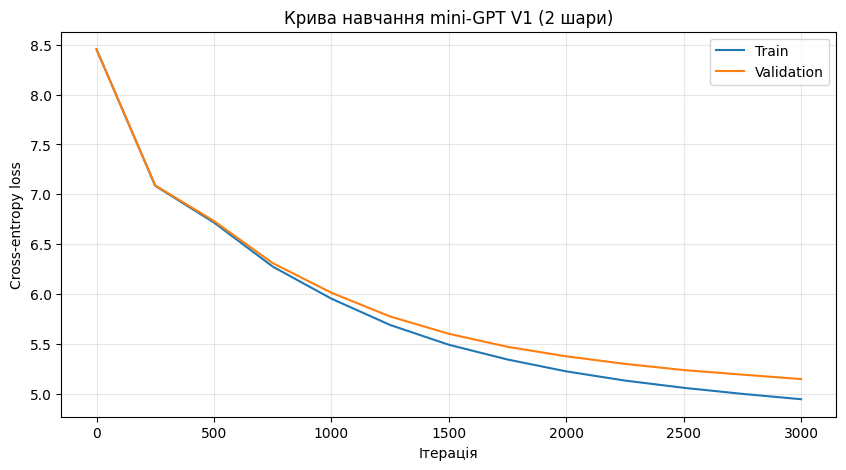

In [10]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_v1["iter"],
    history_v1["train_loss"],
    label="Train"
)

plt.plot(
    history_v1["iter"],
    history_v1["val_loss"],
    label="Validation"
)

plt.title("Крива навчання mini-GPT V1 (2 шари)")
plt.xlabel("Ітерація")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(ARTIFACT_DIR, "mini_gpt_v1_loss.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

In [11]:
model_v2, history_v2, summary_v2 = train_model(
    model_name="mini_gpt_v2",
    n_layers=4
)

Модель: mini_gpt_v2
Кількість параметрів: 1836192
iter    0 | train_loss=8.457 | val_loss=8.463 | 0.0 хв
iter  250 | train_loss=7.047 | val_loss=7.057 | 0.1 хв
iter  500 | train_loss=6.534 | val_loss=6.554 | 0.2 хв
iter  750 | train_loss=6.114 | val_loss=6.156 | 0.3 хв
iter 1000 | train_loss=5.758 | val_loss=5.831 | 0.4 хв
iter 1250 | train_loss=5.487 | val_loss=5.586 | 0.5 хв
iter 1500 | train_loss=5.295 | val_loss=5.418 | 0.6 хв
iter 1750 | train_loss=5.163 | val_loss=5.299 | 0.7 хв
iter 2000 | train_loss=5.056 | val_loss=5.217 | 0.8 хв
iter 2250 | train_loss=4.972 | val_loss=5.149 | 0.9 хв
iter 2500 | train_loss=4.905 | val_loss=5.091 | 1.0 хв
iter 2750 | train_loss=4.844 | val_loss=5.049 | 1.1 хв
iter 2999 | train_loss=4.793 | val_loss=5.007 | 1.2 хв

Тренування завершено!
Тривалість: 1.20 хв
Найкращий val_loss: 5.0068
Найкраща ітерація: 2999


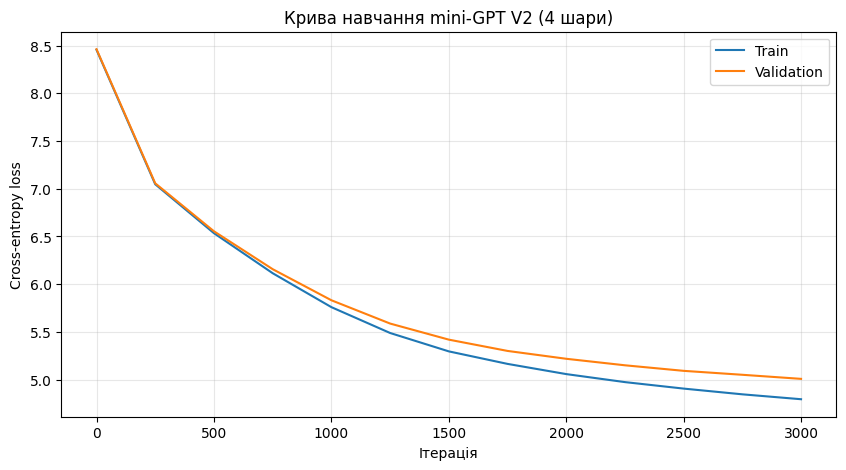

In [12]:
plt.figure(figsize=(10, 5))

plt.plot(
    history_v2["iter"],
    history_v2["train_loss"],
    label="Train"
)

plt.plot(
    history_v2["iter"],
    history_v2["val_loss"],
    label="Validation"
)

plt.title("Крива навчання mini-GPT V2 (4 шари)")
plt.xlabel("Ітерація")
plt.ylabel("Cross-entropy loss")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig(
    os.path.join(ARTIFACT_DIR, "mini_gpt_v2_loss.png"),
    dpi=150,
    bbox_inches="tight"
)

plt.show()

На власному корпусі українськомовних новин я навчила дві конфігурації mini-GPT. Перша модель містить два шари трансформера, а друга — чотири. Інші гіперпараметри залишила однаковими.

Модель V1 навчалася протягом 0,83 хвилини та отримала найкраще значення `val_loss` 5,1464. Модель V2 навчалася протягом 1,20 хвилини та отримала значення `val_loss` 5,0068.

На графіках обох моделей спостерігається поступове зменшення функції втрат. Явних ознак перенавчання немає, хоча різниця між навчальною та валідаційною кривими поступово збільшується.

Таким чином, збільшення кількості шарів трансформера дозволило покращити результат на валідаційній вибірці, але збільшило кількість параметрів моделі та тривалість навчання. Остаточно оцінити якість моделей можна після перевірки генерації тексту.

In [13]:
prompt = "В Україні сьогодні"

for model_name in ["mini_gpt_v1", "mini_gpt_v2"]:

    checkpoint = torch.load(
        os.path.join(MODELS_DIR, f"{model_name.replace('mini_gpt', 'minigpt')}.pt"),
        map_location=device
    )

    model = MiniGPT(**checkpoint["config"]).to(device)
    model.load_state_dict(checkpoint["model_state_dict"])
    model.eval()

    input_ids = torch.tensor(
        [gpt_tokenizer.encode(prompt).ids],
        dtype=torch.long,
        device=device
    )

    torch.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

    generated = model.generate(
        input_ids,
        max_new_tokens=100,
        temperature=0.8,
        top_k=40
    )

    text = gpt_tokenizer.decode(generated[0].tolist())

    print(f"\n=== {model_name} ===")
    print(f"Val loss: {checkpoint['val_loss']:.4f}")
    print(text)

    del model


=== mini_gpt_v1 ===
Val loss: 5.1464
В Україні сьогодні в іншому рівні 61. Американський ліфеми. А в Норвегантопочка. Всилисьменниця, він розповів, що вони зуска, коли "ФУсі дипанітельцинський ситне місце натомів, що це не може бути лекнав. Ілійські, він не менше ніж не потрібно, що стільнемтог, але й інші, це чудовий,

=== mini_gpt_v2 ===
Val loss: 5.0068
В Україні сьогодні в іншому.Дараслідок року Допераміна Абовиченка у Франка. Вакторі, що на роботу до лікарні та Мегрландії, що вазі, але не знецтва. Це може бути її, що ви має це не вийдуть кошти.Джя нею на те, він має бути солі.Як кожен стільнем, що не мають незмінно впливає відмінний


Для порівняння якості генерації обох моделей я використала однаковий початковий текст «В Україні сьогодні» та однакові параметри генерації: `temperature = 0.8`, `top_k = 40`, `max_new_tokens = 100`.

**Модель V1 (2 шари):**
Модель навчилася генерувати окремі українські слова, словосполучення та розділові знаки. Проте в тексті присутня велика кількість вигаданих слів, граматичних помилок, а між реченнями відсутній логічний зв'язок.

**Модель V2 (4 шари):**
Модель отримала нижче значення `val_loss` та змогла сформувати окремі більш природні словосполучення, наприклад «на роботу до лікарні» та «не вийдуть кошти». Проте текст також містить вигадані слова та не має цілісного змісту.

Обидві моделі засвоїли певні закономірності української мови та частково відтворюють стиль новин. Модель V2 показала кращий результат за функцією втрат, однак за одним прикладом генерації не можна однозначно стверджувати, що вона генерує якісніший текст.

Для покращення результатів можна збільшити обсяг текстового корпусу, розмір моделі та кількість ітерацій навчання.

---
## 4. Playground готових моделей

Тур по задачах через `pipeline()` — на основі [HF LLM Course, Chapter 1, §3](https://huggingface.co/learn/llm-course/en/chapter1/3).

_Зверніть увагу_: в межах попередніх завдань Ви могли завантажити памʼять "під завʼязку", тому для безпроблемного виконання наступних секцій вивільніть памʼять:

1. **Спершу збережіть усе потрібне на диск** — чекпоінти mini-GPT (`models/minigpt_v*.pt`), токенізатори, `results.csv`. Секції 4-6 від змінних секцій 1-3 не залежать, тож після цього їх можна сміливо видаляти.
2. **Видаліть великі обʼєкти** — моделі, оптимізатори, тензори `train_data`/`val_data`, корпус і `DataFrame`-и — і зберіть сміття:
   ```python
   import gc, torch

   del model, optimizer, train_data, val_data, corpus_text  # підставте свої імена змінних
   gc.collect()
   if torch.cuda.is_available():
       torch.cuda.empty_cache()
       print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")
   ```
   Памʼять звільниться лише тоді, коли на обʼєкт не лишиться **жодного** посилання: зверніть увагу на копії в інших змінних, списках і словниках (наприклад, словник із кількома варіантами моделей).
3. **Перевірте, що памʼять справді звільнилась**: індикатор RAM/GPU вгорі праворуч.
4. **У самій секції 4 не тримайте всі pipeline-и одночасно**: кожен `pipeline(...)` завантажує окрему модель. Перевикористовуйте одну змінну (як `classifier` нижче) або робіть `del` + `gc.collect()` після кожної задачі.
5. **Стежте за диском**: моделі кешуються в `~/.cache/huggingface/hub`, і кілька моделей для summarization/translation легко займуть кілька ГБ. Переглянути й почистити кеш: `hf cache ls` / `hf cache rm <id моделі>`.

In [ ]:
pd.DataFrame([summary_v1, summary_v2]).to_csv(
    os.path.join(ARTIFACT_DIR, "results.csv"), index=False
)

In [15]:
import gc
import torch

for name in [
    "model_v1", "model_v2", "checkpoint",
    "train_data", "val_data", "data",
    "all_ids", "news_df", "news_texts",
    "corpus_text", "dataset", "xb", "yb",
    "generated", "input_ids"
]:
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()

print(f"GPU: зайнято {torch.cuda.memory_allocated() / 1e9:.2f} GB")

GPU: зайнято 0.02 GB


### 4.0. Запустіть приклади виконання різних NLP задач

In [17]:
# Sentiment analysis
from transformers import pipeline

classifier = pipeline("sentiment-analysis", model="distilbert/distilbert-base-uncased-finetuned-sst-2-english")
print(classifier("I've been waiting for a HuggingFace course my whole life."))
print(classifier(
    ["I've been waiting for a HuggingFace course my whole life.", "I hate this so much!"]
))

del classifier
gc.collect()
torch.cuda.empty_cache()

[transformers] No model was supplied, defaulted to distilbert/distilbert-base-uncased-finetuned-sst-2-english and revision 714eb0f.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/629 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

[{'label': 'POSITIVE', 'score': 0.9598046541213989}]
[{'label': 'POSITIVE', 'score': 0.9598046541213989}, {'label': 'NEGATIVE', 'score': 0.9994558691978455}]


In [18]:
# Zero-shot classification
from transformers import pipeline

classifier = pipeline("zero-shot-classification", model="facebook/bart-large-mnli")
display(classifier(
    "This is a course about the Transformers library",
    candidate_labels=["education", "politics", "business"],
))

del classifier
gc.collect()
torch.cuda.empty_cache()

[transformers] No model was supplied, defaulted to facebook/bart-large-mnli and revision d7645e1.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.15k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.63GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/515 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

{'sequence': 'This is a course about the Transformers library',
 'labels': ['education', 'business', 'politics'],
 'scores': [0.844595193862915, 0.11197695881128311, 0.04342786595225334]}

In [19]:
# Під час початкового запуску max_length було перевизначено; тепер явно обмежуємо генерацію.
# Text generation
from transformers import pipeline

generator = pipeline("text-generation", model="HuggingFaceTB/SmolLM3-3B", dtype=torch.float16 if torch.cuda.is_available() else torch.float32)
print(generator("In this course, we will teach you how to"))

del generator
gc.collect()
torch.cuda.empty_cache()
generator = pipeline("text-generation", model="distilgpt2")
print(generator(
    "In this course, we will teach you how to",
    max_new_tokens=30, do_sample=True,
    num_return_sequences=2,
))

del generator
gc.collect()
torch.cuda.empty_cache()

[transformers] No model was supplied, defaulted to HuggingFaceTB/SmolLM3-3B and revision a07cc9a.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/26.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/326 [00:00<?, ?it/s]

... (15 outputs left out)

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_length', 'num_return_sequences'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=256) and `max_length`(=30) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer GPT2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


[{'generated_text': 'In this course, we will teach you how to make the most of the biggest changes in the world in the future.\n\n\n\n\nI will provide a series of short videos explaining why this course is important to you.\nThe main lesson of the course is what to do about it.\nTo be clear, we will not teach you how to make the largest change in the world in the future.\nThe main lesson of the course is how to make the biggest change in the world in the future.\nThe key lesson of the course is how to make the biggest change in the world in the future.\nThe key lesson of the course is how to make the biggest change in the world in the future.\nThe key lesson of the course is the key lesson of the course is how to make the biggest change in the world in the future.\nThe key lesson of the course is how to make the biggest change in the world in the future.\nThe key lesson of the course is how to make the biggest change in the world in the future.\nThe key lesson of the course is how to m

In [20]:
# Fill-mask
from transformers import pipeline

unmasker = pipeline("fill-mask", model="distilbert/distilroberta-base")
display(unmasker("This course will teach you all about <mask> models.", top_k=2))

del unmasker
gc.collect()
torch.cuda.empty_cache()

[transformers] No model was supplied, defaulted to distilbert/distilroberta-base and revision fb53ab8.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/480 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  331MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/106 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: distilbert/distilroberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

[{'score': 0.19619743525981903,
  'token': 30412,
  'token_str': ' mathematical',
  'sequence': 'This course will teach you all about mathematical models.'},
 {'score': 0.04052695631980896,
  'token': 38163,
  'token_str': ' computational',
  'sequence': 'This course will teach you all about computational models.'}]

In [21]:
# Named entity recognition
from transformers import pipeline

ner = pipeline("ner", model="dbmdz/bert-large-cased-finetuned-conll03-english", aggregation_strategy="simple")
display(ner("My name is Sylvain and I work at Hugging Face in Brooklyn."))

del ner
gc.collect()
torch.cuda.empty_cache()

[transformers] No model was supplied, defaulted to dbmdz/bert-large-cased-finetuned-conll03-english and revision 4c53496.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/998 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.33GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

[transformers] BertForTokenClassification LOAD REPORT from: dbmdz/bert-large-cased-finetuned-conll03-english
Key                      | Status     |  | 
-------------------------+------------+--+-
bert.pooler.dense.weight | UNEXPECTED |  | 
bert.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/60.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/213k [00:00<?, ?B/s]

[{'entity_group': 'PER',
  'score': np.float32(0.9981694),
  'word': 'Sylvain',
  'start': 11,
  'end': 18},
 {'entity_group': 'ORG',
  'score': np.float32(0.9796019),
  'word': 'Hugging Face',
  'start': 33,
  'end': 45},
 {'entity_group': 'LOC',
  'score': np.float32(0.9932106),
  'word': 'Brooklyn',
  'start': 49,
  'end': 57}]

In [22]:
# Question answering
from transformers import pipeline

question_answerer = pipeline("table-question-answering", model="google/tapas-base-finetuned-wtq")
display(question_answerer(
    query="How many stars does the transformers repository have?",
    table={"Repository":["Transformers","Datasets","Tokenizers"],"Stars":["36542","4512","3934"],"Contributors":["651","77","34"],"Programming language":["Python","Python","Rust, Python and NodeJS"]},
))

del question_answerer
gc.collect()
torch.cuda.empty_cache()

[transformers] No model was supplied, defaulted to google/tapas-base-finetuned-wtq and revision e3dde19.
Using a pipeline without specifying a model name and revision in production is not recommended.


config.json:   0%|          | 0.00/1.66k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  443MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/490 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/262k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  443MB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/154 [00:00<?, ?B/s]

{'answer': 'AVERAGE > 36542',
 'coordinates': [(0, 1)],
 'cells': ['36542'],
 'aggregator': 'AVERAGE'}

### 4.1. Свої приклади

Повторіть **усі 6 задач** вище (sentiment-analysis, zero-shot-classification, text-generation, fill-mask, NER, table-question-answering), але замість дефолтних англійських прикладів — придумайте й використайте **свої українськомовні приклади** для кожної задачі (якщо потрібно, підберіть відповідні моделі зі знанням української мови). Для виконання цього завдання постворюйте клітинки нижче.

In [23]:
from transformers import pipeline

sentiment_ua = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment"
)

texts = [
    "Мені дуже сподобався новий курс зі штучного інтелекту!",
    "Я розчарована результатами і незадоволена навчанням.",
    "Сьогодні заняття розпочалося о дев'ятій годині."
]

results = sentiment_ua(texts)

for text, result in zip(texts, results):
    print("Текст:", text)
    print("Тональність:", result["label"])
    print(f"Впевненість: {result['score']:.2%}")
    print()

del sentiment_ua
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/841 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.11GB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

sentencepiece.bpe.model: reconstructing file:   0%|          |  0.00B / 5.07MB            

sentencepiece.bpe.model: downloading bytes:           |  0.00B            

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Текст: Мені дуже сподобався новий курс зі штучного інтелекту!
Тональність: positive
Впевненість: 89.04%

Текст: Я розчарована результатами і незадоволена навчанням.
Тональність: negative
Впевненість: 89.71%

Текст: Сьогодні заняття розпочалося о дев'ятій годині.
Тональність: neutral
Впевненість: 75.42%



In [24]:
from transformers import pipeline

classifier_ua = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
)

result = classifier_ua(
    "В Україні відкрили новий університетський центр дослідження штучного інтелекту.",
    candidate_labels=[
        "освіта",
        "політика",
        "спорт",
        "економіка"
    ],
    hypothesis_template="Цей текст стосується теми {}."
)

print("Текст:", result["sequence"])

for label, score in zip(result["labels"], result["scores"]):
    print(f"{label}: {score:.2%}")

del classifier_ua
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/1.07k [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.26k [00:00<?, ?B/s]

... (3 outputs left out)

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/286 [00:00<?, ?B/s]

Текст: В Україні відкрили новий університетський центр дослідження штучного інтелекту.
освіта: 34.36%
політика: 26.09%
спорт: 19.85%
економіка: 19.70%


In [29]:
import gc
import torch
from transformers import pipeline

# Звільнення пам'яті
globals().pop("classifier_ua", None)
gc.collect()
torch.cuda.empty_cache()

# Завантаження альтернативної моделі
classifier_ua = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
    device=0 if torch.cuda.is_available() else -1
)

result = classifier_ua(
    "В Україні відкрили новий університетський центр дослідження штучного інтелекту.",
    candidate_labels=[
        "освіта",
        "політика",
        "спорт",
        "економіка"
    ],
    hypothesis_template="Цей текст стосується теми {}."
)

print("Текст:", result["sequence"])

for label, score in zip(result["labels"], result["scores"]):
    print(f"{label}: {score:.2%}")

del classifier_ua
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/1.09k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  558MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/467 [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 16.3MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/23.0 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/173 [00:00<?, ?B/s]

Текст: В Україні відкрили новий університетський центр дослідження штучного інтелекту.
освіта: 98.32%
політика: 1.10%
економіка: 0.38%
спорт: 0.20%


Для класифікації українськомовного тексту я порівняла дві багатомовні моделі:

- `MoritzLaurer/mDeBERTa-v3-base-mnli-xnli`;
- `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7`.

Для обох моделей використала однаковий текст та однакові категорії.

| Категорія | Перша модель | Друга модель |
|---|---:|---:|
| Освіта | 34,36% | 98,32% |
| Політика | 26,09% | 1,10% |
| Спорт | 19,85% | 0,20% |
| Економіка | 19,70% | 0,38% |

Обидві моделі правильно визначили категорію «освіта», проте друга модель показала значно вищу впевненість та чіткіше розмежувала запропоновані категорії.

Отже, вибір попередньо навченої моделі суттєво впливає на результат класифікації українськомовного тексту. На дослідженому прикладі друга модель показала кращий результат.

In [25]:
from transformers import pipeline

generator_ua = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-0.5B-Instruct",
    device=0 if torch.cuda.is_available() else -1
)

messages = [
    {
        "role": "user",
        "content": "Напиши коротку новину українською мовою про використання штучного інтелекту в освіті."
    }
]

result = generator_ua(
    messages,
    max_new_tokens=150,
    do_sample=True,
    temperature=0.7,
    top_p=0.9
)

print(result[0]["generated_text"][-1]["content"])

del generator_ua
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/659 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  988MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/290 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Passing `generation_config` together with generation-related arguments=({'max_new_tokens', 'temperature', 'top_p', 'do_sample'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer Qwen2Tokenizer. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Використання штучного інтелекту в освіті - це традиція, яка дозволяє до обговорення розумінь та обмеженняться їховним відповідоми. Ідеє, що усі можливі роботи, включаючи розуміння та обговорення розумінь, мають вигляд штучного інтелекту, а не використання штучного інтелекту в освіті


In [30]:
import gc
import torch
from transformers import pipeline

# Звільнення пам'яті
for name in [
    "generator_ua", "generator", "classifier",
    "classifier_ua", "sentiment_ua", "ner",
    "ner_ua", "unmasker", "unmasker_ua",
    "tqa", "tqa_ua"
]:
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()

# Завантаження потужнішої моделі
generator_ua = pipeline(
    "text-generation",
    model="Qwen/Qwen2.5-3B-Instruct",
    dtype=torch.float16,
    device=0 if torch.cuda.is_available() else -1
)

messages = [
    {
        "role": "user",
        "content": "Напиши коротку новину українською мовою про використання штучного інтелекту в освіті."
    }
]

result = generator_ua(
    messages,
    max_new_tokens=150,
    do_sample=True,
    temperature=0.7,
    top_p=0.9
)

print(result[0]["generated_text"][-1]["content"])

del generator_ua
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/661 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/35.6k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

... (2 outputs left out)

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[transformers] Both `max_new_tokens` (=150) and `max_length`(=20) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Ваше життя в школі може змінитися: Альфа Централ впроваджує першу у світі систему зчитування тексту через використання штучного інтелекту! Тепер учні можуть отримувати додаткову допомогу з текстовими матеріалами, безперечно з читаючи складні та довгі статті. Забарвлення навчання, підтримка розвитку та змішування дос


Для генерації українськомовного тексту я порівняла дві моделі:

- `Qwen/Qwen2.5-0.5B-Instruct`;
- `Qwen/Qwen2.5-3B-Instruct`.

Для обох моделей використала однаковий промпт та однакові параметри генерації.

Перша модель генерувала текст із великою кількістю граматичних помилок, повторень та нелогічних словосполучень. Друга модель сформувала більш зв'язний текст, який краще відповідає заданій тематиці та стилю новини.

Проте навіть у більшої моделі залишилися граматичні помилки та непідтверджені факти, а текст не був завершений через обмеження кількості токенів.

Отже, збільшення розміру моделі в цьому експерименті позитивно вплинуло на якість генерації, але не забезпечило повністю грамотного та достовірного результату.

In [26]:
from transformers import pipeline

unmasker_ua = pipeline(
    "fill-mask",
    model="FacebookAI/xlm-roberta-base"
)

text = "Студенти університету вивчають штучний <mask>."

results = unmasker_ua(text, top_k=5)

for result in results:
    print("Слово:", result["token_str"])
    print(f"Ймовірність: {result['score']:.2%}")
    print("Речення:", result["sequence"])
    print()

del unmasker_ua
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.12GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] XLMRobertaForMaskedLM LOAD REPORT from: FacebookAI/xlm-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

Слово: світ
Ймовірність: 6.92%
Речення: Студенти університету вивчають штучний світ .

Слово: матеріал
Ймовірність: 5.11%
Речення: Студенти університету вивчають штучний матеріал .

Слово: дизайн
Ймовірність: 3.24%
Речення: Студенти університету вивчають штучний дизайн .

Слово: космос
Ймовірність: 2.98%
Речення: Студенти університету вивчають штучний космос .

Слово: контроль
Ймовірність: 2.90%
Речення: Студенти університету вивчають штучний контроль .



In [31]:
import gc
import torch
from transformers import pipeline

globals().pop("generator_ua", None)

gc.collect()
torch.cuda.empty_cache()

unmasker_ua = pipeline(
    "fill-mask",
    model="youscan/ukr-roberta-base"
)

mask = unmasker_ua.tokenizer.mask_token
text = f"Студенти університету вивчають штучний {mask}."

results = unmasker_ua(text, top_k=5)

for result in results:
    print("Слово:", result["token_str"])
    print(f"Ймовірність: {result['score']:.2%}")
    print("Речення:", result["sequence"])
    print()

print("Токенізація слова 'інтелект':",
      unmasker_ua.tokenizer.tokenize(" інтелект"))

del unmasker_ua
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  507MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/204 [00:00<?, ?it/s]

[transformers] RobertaForMaskedLM LOAD REPORT from: youscan/ukr-roberta-base
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


tokenizer_config.json:   0%|          | 0.00/16.0 [00:00<?, ?B/s]

... (2 outputs left out)

vocab.json:   0%|          | 0.00/1.86M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.40M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Слово:  інтелект
Ймовірність: 58.31%
Речення: Студенти університету вивчають штучний  інтелект.

Слово:  імунітет
Ймовірність: 6.80%
Речення: Студенти університету вивчають штучний  імунітет.

Слово:  зір
Ймовірність: 6.17%
Речення: Студенти університету вивчають штучний  зір.

Слово:  матеріал
Ймовірність: 5.08%
Речення: Студенти університету вивчають штучний  матеріал.

Слово:  рак
Ймовірність: 1.84%
Речення: Студенти університету вивчають штучний  рак.

Токенізація слова 'інтелект': ['ĠÑĸÐ½ÑĤÐµÐ»ÐµÐºÑĤ']


Для заповнення пропущеного слова я порівняла дві моделі:

- `FacebookAI/xlm-roberta-base`;
- `youscan/ukr-roberta-base`.

Для обох моделей використала однакове речення: «Студенти університету вивчають штучний `<mask>`.»

| Місце | XLM-RoBERTa | UKR-RoBERTa |
|---|---|---|
| 1 | світ — 6,92% | інтелект — 58,31% |
| 2 | матеріал — 5,11% | імунітет — 6,80% |
| 3 | дизайн — 3,24% | зір — 6,17% |
| 4 | космос — 2,98% | матеріал — 5,08% |
| 5 | контроль — 2,90% | рак — 1,84% |

Перша модель не запропонувала очікуване слово серед п'яти варіантів. Натомість друга модель поставила слово «інтелект» на перше місце з ймовірністю 58,31%.

Додаткова перевірка показала, що в токенізаторі другої моделі слово «інтелект» представлене одним токеном.

Отже, на дослідженому прикладі модель, спеціалізована на українській мові, показала значно кращий результат, ніж багатомовна модель.

In [27]:
from transformers import pipeline

ner_ua = pipeline(
    "ner",
    model="Davlan/xlm-roberta-base-ner-hrl",
    aggregation_strategy="simple"
)

text = "Тарас Шевченко народився в Україні. Студенти відвідали Житомирську політехніку."

results = ner_ua(text)

for result in results:
    print("Сутність:", result["word"])
    print("Тип:", result["entity_group"])
    print(f"Впевненість: {result['score']:.2%}")
    print()

del ner_ua
gc.collect()
torch.cuda.empty_cache()

config.json:   0%|          | 0.00/980 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/211 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

Сутність: Тарас Шевченко
Тип: PER
Впевненість: 99.99%

Сутність: Україні
Тип: LOC
Впевненість: 99.99%

Сутність: Житомирську політехніку
Тип: ORG
Впевненість: 99.95%



In [28]:
from transformers import pipeline
import pandas as pd

tqa_ua = pipeline(
    "table-question-answering",
    model="google/tapas-base-finetuned-wtq"
)

table = pd.DataFrame({
    "Студент": ["Анна", "Олена", "Максим"],
    "Бал": ["95", "88", "76"]
})

questions = [
    "Який бал отримала Анна?",
    "Хто отримав найвищий бал?",
    "Який середній бал студентів?"
]

display(table)

for question in questions:
    result = tqa_ua(table=table, query=question)

    print("Запитання:", question)
    print("Відповідь:", result["answer"])
    print()

del tqa_ua
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

,Студент,Бал
0,Анна,95
1,Олена,88
2,Максим,76


Запитання: Який бал отримала Анна?
Відповідь: Анна

Запитання: Хто отримав найвищий бал?
Відповідь: Максим

Запитання: Який середній бал студентів?
Відповідь: Максим



In [32]:
from transformers import pipeline
import pandas as pd

tqa_ua = pipeline(
    "table-question-answering",
    model="google/tapas-base-finetuned-wtq"
)

table_en = pd.DataFrame({
    "Student": ["Anna", "Olena", "Maksym"],
    "Score": ["95", "88", "76"]
})

questions_en = [
    "What score did Anna receive?",
    "Which student has the highest score?",
    "What is the average score of all students?"
]

for question in questions_en:
    result = tqa_ua(table=table_en, query=question)

    print("Запитання:", question)
    print("Відповідь:", result["answer"])
    print()

del tqa_ua
gc.collect()
torch.cuda.empty_cache()

Loading weights:   0%|          | 0/211 [00:00<?, ?it/s]

Запитання: What score did Anna receive?
Відповідь: AVERAGE > 95

Запитання: Which student has the highest score?
Відповідь: Anna

Запитання: What is the average score of all students?
Відповідь: AVERAGE > 95, 88, 76



Для отримання відповідей на запитання за таблицею я використала модель `google/tapas-base-finetuned-wtq`. Провела два експерименти з однаковими даними, але різними мовами — українською та англійською.

| Запитання | Українськомовний приклад | Англомовний приклад |
|---|---|---|
| Який бал отримала Анна? | Анна | AVERAGE > 95 |
| Хто отримав найвищий бал? | Максим | Anna |
| Який середній бал студентів? | Максим | AVERAGE > 95, 88, 76 |

При використанні української мови модель не надала жодної правильної відповіді. Після перекладу таблиці та запитань англійською мовою модель правильно визначила необхідні комірки та операцію обчислення середнього бала.

Водночас у першому запитанні модель зайво застосувала операцію AVERAGE, а в третьому повернула значення для обчислення середнього, а не готовий числовий результат (86,33).

Отже, експеримент продемонстрував залежність якості відповідей від мовної спеціалізації моделі. Для роботи з українськомовними таблицями можна використовувати попередній переклад даних та запитань англійською мовою.

---
## 5. Порівняння моделей

### 5.1. Оберіть задачу й метрику

Візьміть **одну** задачу зі списку нижче:

| Задача | Метрика | Що потрібно підготувати | Метрика в `evaluate` |
|---|---|---|---|
| sentiment-analysis | Accuracy / F1 | 15-20 своїх речень + правильна мітка (positive/negative) | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy), [`f1`](https://huggingface.co/spaces/evaluate-metric/f1) |
| zero-shot-classification | Accuracy | те саме + фіксований список `candidate_labels` | [`accuracy`](https://huggingface.co/spaces/evaluate-metric/accuracy) |
| NER | F1 (entity-level) | кілька речень + список правильних сутностей (текст + тип) | [`seqeval`](https://huggingface.co/spaces/evaluate-metric/seqeval) |

Усі метрики рахуються через бібліотеку `evaluate` (той самий автор, що й `transformers`/`datasets`):
```python
import evaluate

metric = evaluate.load("rouge")  # або "accuracy", "f1", "seqeval", "squad", "sacrebleu"
metric.compute(predictions=[...], references=[...])
```
Формат `predictions`/`references` трохи відрізняється між метриками — дивіться приклад використання на сторінці кожної метрики (посилання в таблиці) або [HF Evaluate — Quick tour](https://huggingface.co/docs/evaluate/a_quick_tour).

### 5.2. Порівняйте моделі

На обраній задачі порівняйте щонайменше 2 різні моделі на однакових вхідних прикладах — не лише значення метрики, а й швидкість інференсу та розмір моделі (кількість параметрів).

### 5.3. Поекспериментуйте з налаштуваннями

Візьміть модель, що показала кращий результат, і поекспериментуйте з її налаштуваннями (temperature/top-p/top-k для генеративних задач, поріг впевненості для класифікаційних задач тощо) — щонайменше 3 зміни, по одній за раз, щоб зрозуміти, що саме впливає на метрику. Зведіть усі спроби (модель × налаштування → значення метрики) в невелику таблицю.

Коротко письмово: яка модель і яка комбінація налаштувань дала найкращий результат за обраною метрикою, і наскільки суттєво налаштування вплинули порівняно з вибором моделі?

In [34]:
import pandas as pd
import evaluate

candidate_labels = [
    "освіта",
    "політика",
    "спорт",
    "економіка"
]

test_examples = [
    # Освіта
    ("Університет відкрив нову лабораторію робототехніки.", "освіта"),
    ("Студенти розпочали підготовку до зимової сесії.", "освіта"),
    ("У школах запроваджують нову навчальну програму.", "освіта"),
    ("Викладачі пройшли курс підвищення кваліфікації.", "освіта"),
    ("Абітурієнти подали документи на вступ.", "освіта"),

    # Політика
    ("Парламент ухвалив зміни до законодавства.", "політика"),
    ("Депутати обговорили новий законопроєкт.", "політика"),
    ("Президент зустрівся з представниками делегації.", "політика"),
    ("Політичні партії представили свої програми.", "політика"),
    ("Уряд провів переговори щодо міжнародної співпраці.", "політика"),

    # Спорт
    ("Українська команда перемогла у фіналі чемпіонату.", "спорт"),
    ("Футболіст забив вирішальний гол.", "спорт"),
    ("Спортсменка встановила новий світовий рекорд.", "спорт"),
    ("У місті відбувся міжнародний марафон.", "спорт"),
    ("Тренер оголосив склад збірної на наступний матч.", "спорт"),

    # Економіка
    ("Національний банк змінив облікову ставку.", "економіка"),
    ("Рівень інфляції знизився порівняно з минулим роком.", "економіка"),
    ("Підприємства збільшили обсяги експорту.", "економіка"),
    ("Інвестори вкладають кошти в розвиток бізнесу.", "економіка"),
    ("Середня заробітна плата зросла на десять відсотків.", "економіка")
]

test_df = pd.DataFrame(
    test_examples,
    columns=["text", "label"]
)

accuracy_metric = evaluate.load("accuracy")

display(test_df)

print("Кількість прикладів:", len(test_df))
print("\nРозподіл категорій:")
print(test_df["label"].value_counts())

,text,label
0,Університет відкрив нову лабораторію робототех...,освіта
1,Студенти розпочали підготовку до зимової сесії.,освіта
2,У школах запроваджують нову навчальну програму.,освіта
3,Викладачі пройшли курс підвищення кваліфікації.,освіта
4,Абітурієнти подали документи на вступ.,освіта
5,Парламент ухвалив зміни до законодавства.,політика
6,Депутати обговорили новий законопроєкт.,політика
7,Президент зустрівся з представниками делегації.,політика
8,Політичні партії представили свої програми.,політика
9,Уряд провів переговори щодо міжнародної співпр...,політика


Кількість прикладів: 20

Розподіл категорій:
label
освіта       5
політика     5
спорт        5
економіка    5
Name: count, dtype: int64


Для порівняння готових моделей я обрала задачу Zero-shot Classification — класифікацію тексту без додаткового навчання.

Підготувала тестовий набір із 20 українськомовних речень, розподілених порівну між чотирма категоріями: освіта, політика, спорт та економіка. Для кожного речення визначила правильну категорію.

Для оцінювання якості класифікації обрала метрику Accuracy, яка визначає частку правильно класифікованих прикладів від їхньої загальної кількості. Для її обчислення використовую бібліотеку `evaluate`.

In [35]:
import time
import gc
import torch
import pandas as pd

from transformers import pipeline

def evaluate_model(model_name):

    gc.collect()
    torch.cuda.empty_cache()

    classifier = pipeline(
        "zero-shot-classification",
        model=model_name,
        device=0 if torch.cuda.is_available() else -1
    )

    predictions = []
    expected = test_df["label"].tolist()

    # Кількість параметрів
    n_params = sum(
        p.numel() for p in classifier.model.parameters()
    )

    # Попередній запуск для прогріву моделі
    classifier(
        test_df["text"].iloc[0],
        candidate_labels=candidate_labels,
        hypothesis_template="Цей текст стосується теми {}."
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    # Класифікація тестових речень
    for text in test_df["text"]:

        result = classifier(
            text,
            candidate_labels=candidate_labels,
            hypothesis_template="Цей текст стосується теми {}."
        )

        predictions.append(result["labels"][0])

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    duration = time.perf_counter() - start

    # Обчислення Accuracy
    accuracy = accuracy_metric.compute(
        predictions=[
            candidate_labels.index(p) for p in predictions
        ],
        references=[
            candidate_labels.index(e) for e in expected
        ]
    )["accuracy"]

    details = test_df.copy()
    details["prediction"] = predictions
    details["correct"] = details["label"] == details["prediction"]

    summary = {
        "model": model_name,
        "accuracy": accuracy,
        "correct_predictions": int(details["correct"].sum()),
        "total_time_sec": round(duration, 4),
        "avg_time_ms": round(duration / len(test_df) * 1000, 2),
        "parameters": n_params
    }

    print("Модель:", model_name)
    print(f"Accuracy: {accuracy:.2%}")
    print("Правильних відповідей:", summary["correct_predictions"], "/ 20")
    print("Загальний час:", summary["total_time_sec"], "с")
    print("Середній час:", summary["avg_time_ms"], "мс")
    print("Кількість параметрів:", n_params)

    del classifier
    gc.collect()
    torch.cuda.empty_cache()

    return summary, details

In [36]:
summary_m1, details_m1 = evaluate_model(
    "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
)

print("\n" + "=" * 50 + "\n")

summary_m2, details_m2 = evaluate_model(
    "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7"
)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Модель: MoritzLaurer/mDeBERTa-v3-base-mnli-xnli
Accuracy: 100.00%
Правильних відповідей: 20 / 20
Загальний час: 2.1192 с
Середній час: 105.96 мс
Кількість параметрів: 278811651




Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Модель: MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7
Accuracy: 90.00%
Правильних відповідей: 18 / 20
Загальний час: 3.8471 с
Середній час: 192.35 мс
Кількість параметрів: 278811651


In [37]:
comparison_df = pd.DataFrame([
    summary_m1,
    summary_m2
])

display(comparison_df)

# Помилки першої моделі
print("Помилки моделі V1:")
display(details_m1[~details_m1["correct"]])

# Помилки другої моделі
print("Помилки моделі V2:")
display(details_m2[~details_m2["correct"]])

,model,accuracy,correct_predictions,total_time_sec,avg_time_ms,parameters
0,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,1.0,20,2.1192,105.96,278811651
1,MoritzLaurer/mDeBERTa-v3-base-xnli-multilingua...,0.9,18,3.8471,192.35,278811651


Помилки моделі V1:


,text,label,prediction,correct


Помилки моделі V2:


,text,label,prediction,correct
15,Національний банк змінив облікову ставку.,економіка,політика,False
18,Інвестори вкладають кошти в розвиток бізнесу.,економіка,освіта,False


Для порівняння моделей у задачі Zero-shot Classification я використала:

- V1 — `MoritzLaurer/mDeBERTa-v3-base-mnli-xnli`;
- V2 — `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7`.

Обидві моделі перевірила на однаковому наборі з 20 українськомовних речень.

| Показник | Модель V1 | Модель V2 |
|---|---:|---:|
| Accuracy | 100% | 90% |
| Правильних відповідей | 20/20 | 18/20 |
| Загальний час інференсу | 2,1192 с | 3,8471 с |
| Середній час інференсу | 105,96 мс | 192,35 мс |
| Кількість параметрів | 278 811 651 | 278 811 651 |

Друга модель припустилася двох помилок:

- Речення про зміну облікової ставки Національного банку віднесла до політики замість економіки.
- Речення про інвестиції в розвиток бізнесу віднесла до освіти замість економіки.

Перша модель правильно класифікувала всі речення та працювала приблизно в 1,82 раза швидше, хоча обидві моделі мають однакову кількість параметрів.

Цікавим є те, що в попередньому експерименті друга модель показала вищу впевненість на окремому прикладі, проте на більшій тестовій вибірці перша модель виявилася точнішою.

Отже, за результатами проведеного експерименту кращою є модель V1. Водночас тестова вибірка є невеликою, тому отримані результати не можна узагальнювати на всі українськомовні тексти.

In [38]:
import time
import gc
import torch
import pandas as pd
from transformers import pipeline

classifier_best = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=0 if torch.cuda.is_available() else -1
)

templates = [
    "Цей текст стосується теми {}.",
    "Тематика цього тексту — {}.",
    "This text is about {}."
]

experiment_results = []

for template in templates:

    predictions = []
    confidence_scores = []

    # Прогрів моделі
    classifier_best(
        test_df["text"].iloc[0],
        candidate_labels=candidate_labels,
        hypothesis_template=template
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = time.perf_counter()

    for text in test_df["text"]:
        result = classifier_best(
            text,
            candidate_labels=candidate_labels,
            hypothesis_template=template
        )

        predictions.append(result["labels"][0])
        confidence_scores.append(result["scores"][0])

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    duration = time.perf_counter() - start

    accuracy = accuracy_metric.compute(
        predictions=[
            candidate_labels.index(p) for p in predictions
        ],
        references=[
            candidate_labels.index(e)
            for e in test_df["label"]
        ]
    )["accuracy"]

    experiment_results.append({
        "template": template,
        "accuracy": accuracy,
        "avg_confidence": sum(confidence_scores) / len(confidence_scores),
        "avg_time_ms": round(duration / len(test_df) * 1000, 2)
    })

experiments_df = pd.DataFrame(experiment_results)

display(experiments_df)

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

,template,accuracy,avg_confidence,avg_time_ms
0,Цей текст стосується теми {}.,1.0,0.884478,119.64
1,Тематика цього тексту — {}.,1.0,0.812631,127.60
2,This text is about {}.,1.0,0.868942,131.45


Для дослідження впливу налаштувань на результати класифікації я провела три експерименти з моделлю `MoritzLaurer/mDeBERTa-v3-base-mnli-xnli`, змінюючи параметр `hypothesis_template`.

| Шаблон | Accuracy | Середня впевненість | Час інференсу |
|---|---:|---:|---:|
| Цей текст стосується теми {}. | 100% | 88,45% | 119,64 мс |
| Тематика цього тексту — {}. | 100% | 81,26% | 127,60 мс |
| This text is about {}. | 100% | 86,89% | 131,45 мс |

У всіх трьох експериментах модель правильно класифікувала всі 20 речень. Проте зміна шаблону вплинула на середню впевненість моделі.

Найкращий результат показав перший шаблон «Цей текст стосується теми {}.», оскільки він забезпечив найвищу середню впевненість та найменший виміряний час інференсу.

Англомовний шаблон також показав хороші результати, незважаючи на те, що тексти та категорії були українськомовними.

Отже, формулювання шаблону гіпотези може впливати на результати роботи моделі. У моєму експерименті точність залишилася незмінною, але відрізнялися показники впевненості та швидкості. Для більш об'єктивного порівняння швидкості варто провести декілька повторних вимірювань.

In [47]:
import pandas as pd

# Результати завдання 3
minigpt_results = pd.DataFrame([
    summary_v1,
    summary_v2
])

minigpt_results.insert(0, "section", "3.2")
minigpt_results.insert(1, "task", "Mini-GPT")

# Результати завдання 5.2
classification_results = comparison_df.copy()

classification_results.insert(0, "section", "5.2")
classification_results.insert(1, "task", "Zero-shot Classification")

# Результати завдання 5.3
settings_results = experiments_df.copy()

settings_results.insert(0, "section", "5.3")
settings_results.insert(1, "task", "Hypothesis template")
settings_results["model"] = (
    "MoritzLaurer/mDeBERTa-v3-base-mnli-xnli"
)

# Об'єднання результатів
final_results = pd.concat(
    [
        minigpt_results,
        classification_results,
        settings_results
    ],
    ignore_index=True
)

final_results.to_csv(
    os.path.join(ARTIFACT_DIR, "results.csv"),
    index=False,
    encoding="utf-8-sig"
)

display(final_results)

print("Кількість записів:", len(final_results))
print("Файл results.csv успішно збережено!")

,section,task,model,n_layers,parameters,duration_min,best_val_loss,best_iter,accuracy,correct_predictions,total_time_sec,avg_time_ms,template,avg_confidence
0,3.2,Mini-GPT,mini_gpt_v1,2.0,1440416.0,0.825200,5.146448,2999.0,NaN,NaN,NaN,NaN,NaN,NaN
1,3.2,Mini-GPT,mini_gpt_v2,4.0,1836192.0,1.198635,5.006772,2999.0,NaN,NaN,NaN,NaN,NaN,NaN
2,5.2,Zero-shot Classification,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,278811651.0,NaN,NaN,NaN,1.0,20.0,2.1192,105.96,NaN,NaN
3,5.2,Zero-shot Classification,MoritzLaurer/mDeBERTa-v3-base-xnli-multilingua...,NaN,278811651.0,NaN,NaN,NaN,0.9,18.0,3.8471,192.35,NaN,NaN
4,5.3,Hypothesis template,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,119.64,Цей текст стосується теми {}.,0.884478
5,5.3,Hypothesis template,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,127.60,Тематика цього тексту — {}.,0.812631
6,5.3,Hypothesis template,MoritzLaurer/mDeBERTa-v3-base-mnli-xnli,NaN,NaN,NaN,NaN,NaN,1.0,NaN,NaN,131.45,This text is about {}.,0.868942


Кількість записів: 7
Файл results.csv успішно збережено!


---
## 6. Творчий застосунок

Побудуйте невеликий Gradio-застосунок на основі будь-якої готової моделі з розділів 4-5 — тема й формат повністю на ваш вибір, заохочується творчість і щось не зовсім очевидне (не просто "ще один чат-бот"). Це може бути й генеративна LLM через `transformers` (`AutoModelForCausalLM`/`AutoTokenizer` або `pipeline("text-generation", ...)`, той самий патерн, що й у демо 4.1-4.2 на Qwen) — `text-generation` уже входить до обов'язкових 8 задач розділу 4, тож це не вихід за межі завдання. Головне — щоб застосунок реально запускався і демонстрував конкретну, зрозумілу користувацьку цінність.

In [40]:
import gc
import torch
import gradio as gr

from transformers import pipeline

# Звільнення пам'яті
for name in [
    "classifier_best", "classifier_ua", "classifier",
    "sentiment_ua", "generator_ua", "generator",
    "ner", "ner_ua", "unmasker", "unmasker_ua",
    "tqa", "tqa_ua"
]:
    globals().pop(name, None)

gc.collect()
torch.cuda.empty_cache()

DEVICE = 0 if torch.cuda.is_available() else -1

# Класифікація новин
news_classifier = pipeline(
    "zero-shot-classification",
    model="MoritzLaurer/mDeBERTa-v3-base-mnli-xnli",
    device=DEVICE
)

# Аналіз тональності
news_sentiment = pipeline(
    "sentiment-analysis",
    model="cardiffnlp/twitter-xlm-roberta-base-sentiment",
    device=DEVICE
)

# Розпізнавання іменованих сутностей
news_ner = pipeline(
    "ner",
    model="Davlan/xlm-roberta-base-ner-hrl",
    aggregation_strategy="simple",
    device=DEVICE
)

print("Усі три моделі готові до роботи!")

Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Усі три моделі готові до роботи!


In [41]:
import pandas as pd
import html

def analyze_news(text):

    if not text or not text.strip():
        raise gr.Error("Введіть текст новини.")

    if len(text) > 1500:
        raise gr.Error("Максимальна довжина тексту — 1500 символів.")

    # Класифікація
    classification = news_classifier(
        text,
        candidate_labels=[
            "освіта",
            "політика",
            "спорт",
            "економіка"
        ],
        hypothesis_template="Цей текст стосується теми {}."
    )

    categories = {
        label.capitalize(): float(score)
        for label, score in zip(
            classification["labels"],
            classification["scores"]
        )
    }

    # Аналіз тональності
    sentiment = news_sentiment(
        text,
        truncation=True,
        max_length=512
    )[0]

    sentiment_names = {
        "positive": "Позитивна",
        "negative": "Негативна",
        "neutral": "Нейтральна"
    }

    sentiment_label = sentiment_names.get(
        sentiment["label"],
        sentiment["label"]
    )

    sentiment_result = {
        sentiment_label: float(sentiment["score"])
    }

    # Розпізнавання сутностей
    entities = news_ner(text)

    entity_types = {
        "PER": "Особа",
        "ORG": "Організація",
        "LOC": "Місце",
        "MISC": "Інше"
    }

    rows = []

    for entity in entities:
        rows.append([
            entity["word"],
            entity_types.get(
                entity["entity_group"],
                entity["entity_group"]
            ),
            f"{entity['score']:.2%}"
        ])

    entities_df = pd.DataFrame(
        rows,
        columns=["Сутність", "Тип", "Впевненість"]
    )

    return categories, sentiment_result, entities_df


print("Функція аналізу готова!")

Функція аналізу готова!


In [42]:
css = """
.gradio-container {
    max-width: 1100px !important;
    margin: auto !important;
}

#hero {
    padding: 32px 0 20px;
}

#hero h1 {
    font-size: 42px;
    letter-spacing: -2px;
    font-weight: 700;
}

#analyze-btn {
    min-height: 48px;
    font-weight: 600;
}

#footer {
    text-align: center;
    opacity: 0.6;
    padding: 24px;
}
"""

with gr.Blocks(title="NewsLens") as demo:

    gr.Markdown(
        """
        # NewsLens
        **AI-аналізатор українськомовних новин**

        Зрозумійте більше, ніж написано.
        """,
        elem_id="hero"
    )

    with gr.Row():

        with gr.Column(scale=1):

            news_input = gr.Textbox(
                label="Текст новини",
                placeholder="Вставте текст новини для аналізу...",
                lines=10,
                max_lines=15
            )

            gr.Markdown("Максимум 1500 символів.")

            analyze_btn = gr.Button(
                "Аналізувати новину",
                variant="primary",
                elem_id="analyze-btn"
            )

            clear_btn = gr.ClearButton(
                value="Очистити"
            )

        with gr.Column(scale=1):

            gr.Markdown("### Результати аналізу")

            category_output = gr.Label(
                label="Тематична класифікація",
                num_top_classes=4
            )

            sentiment_output = gr.Label(
                label="Емоційна тональність"
            )

    gr.Markdown("### Іменовані сутності")

    entities_output = gr.Dataframe(
        headers=["Сутність", "Тип", "Впевненість"],
        interactive=False
    )

    gr.Markdown("### Спробуйте готові приклади")

    gr.Examples(
        examples=[
            [
                "У Житомирській політехніці відкрили нову лабораторію штучного інтелекту. Студенти отримають можливість працювати із сучасними технологіями."
            ],
            [
                "Українська збірна здобула перемогу на міжнародному чемпіонаті в Парижі."
            ],
            [
                "Національний банк України повідомив про зростання інфляції та погіршення економічних прогнозів."
            ]
        ],
        inputs=news_input
    )

    analyze_btn.click(
        fn=analyze_news,
        inputs=news_input,
        outputs=[
            category_output,
            sentiment_output,
            entities_output
        ]
    )

    clear_btn.add([
        news_input,
        category_output,
        sentiment_output,
        entities_output
    ])

    gr.Markdown(
        "NewsLens · NLP Laboratory Project · 2026",
        elem_id="footer"
    )

print("Інтерфейс успішно створено!")

Інтерфейс успішно створено!


In [ ]:
theme = gr.themes.Soft(primary_hue="blue", neutral_hue="slate")
# У Colab створюється тимчасове публічне посилання; локально — лише localhost.
demo.launch(share="google.colab" in sys.modules, theme=theme, css=css,
            show_error=True, prevent_thread_lock=True)

### NewsLens — AI-аналізатор українськомовних новин

Для виконання творчого завдання я розробила застосунок NewsLens за допомогою бібліотеки Gradio. Основною ідеєю застосунку є автоматичний аналіз українськомовних новин та представлення результатів у зручному і зрозумілому для користувача форматі.

Для реалізації застосунку використала три попередньо навчені моделі, які досліджувала під час виконання попередніх завдань:

- `MoritzLaurer/mDeBERTa-v3-base-mnli-xnli` — тематична класифікація тексту;
- `cardiffnlp/twitter-xlm-roberta-base-sentiment` — аналіз емоційної тональності;
- `Davlan/xlm-roberta-base-ner-hrl` — розпізнавання іменованих сутностей.

**Основний функціонал застосунку:**

- введення власного тексту новини;
- визначення тематичної категорії (освіта, політика, спорт, економіка);
- визначення емоційної тональності тексту;
- розпізнавання імен людей, назв організацій та географічних назв;
- візуалізація оцінок впевненості моделей;
- використання готових прикладів для тестування;
- очищення введеного тексту та результатів аналізу.

Особливу увагу я приділила дизайну інтерфейсу та зручності його використання. Інтерфейс реалізовано українською мовою з використанням Gradio Blocks та CSS. Для оформлення обрала темну кольорову гаму із синіми акцентами, мінімалістичний стиль та чітке розділення функціональних блоків.

**Результати тестування**

Для перевірки роботи застосунку використала текст новини про відкриття лабораторії штучного інтелекту в Житомирській політехніці.

| Показник | Результат |
|---|---|
| Тематична категорія | Освіта |
| Впевненість класифікації | 94% |
| Емоційна тональність | Позитивна |
| Впевненість визначення тональності | 69% |
| Розпізнана сутність | Житомирській політехніці |
| Тип сутності | Організація |
| Впевненість розпізнавання | 99,88% |

**Висновок**

У результаті виконання творчого завдання я створила функціональний AI-застосунок, який поєднує три різні задачі обробки природної мови в одному інтерфейсі. Під час тестування всі три моделі успішно опрацювали запропонований текст.

Розроблений застосунок демонструє практичне використання готових моделей штучного інтелекту для аналізу українськомовного контенту. У майбутньому його можна вдосконалити, розширивши кількість тематичних категорій, додавши автоматичне скорочення новин та можливість аналізу текстів більшого обсягу.

Наразі застосунок підтримує чотири тематичні категорії та тексти довжиною до 1500 символів. Доступ до нього здійснюється за тимчасовим посиланням Gradio без авторизації, поки активне середовище виконання Google Colab.

![NewsLens — результат тестування](attachment:image(20261124-212059).png)
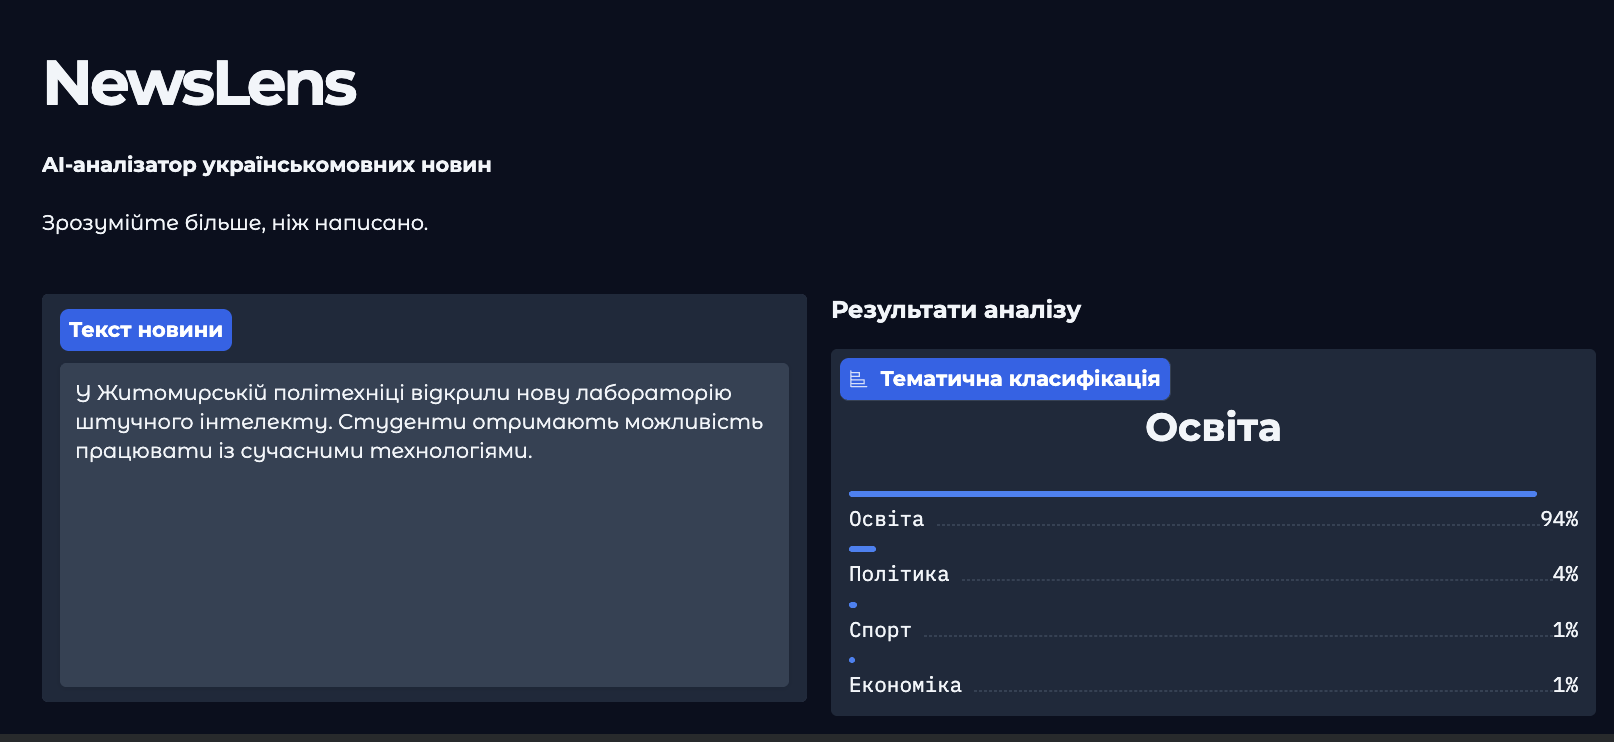

![NewsLens — результат тестування](attachment:image(20261124-212105).png)
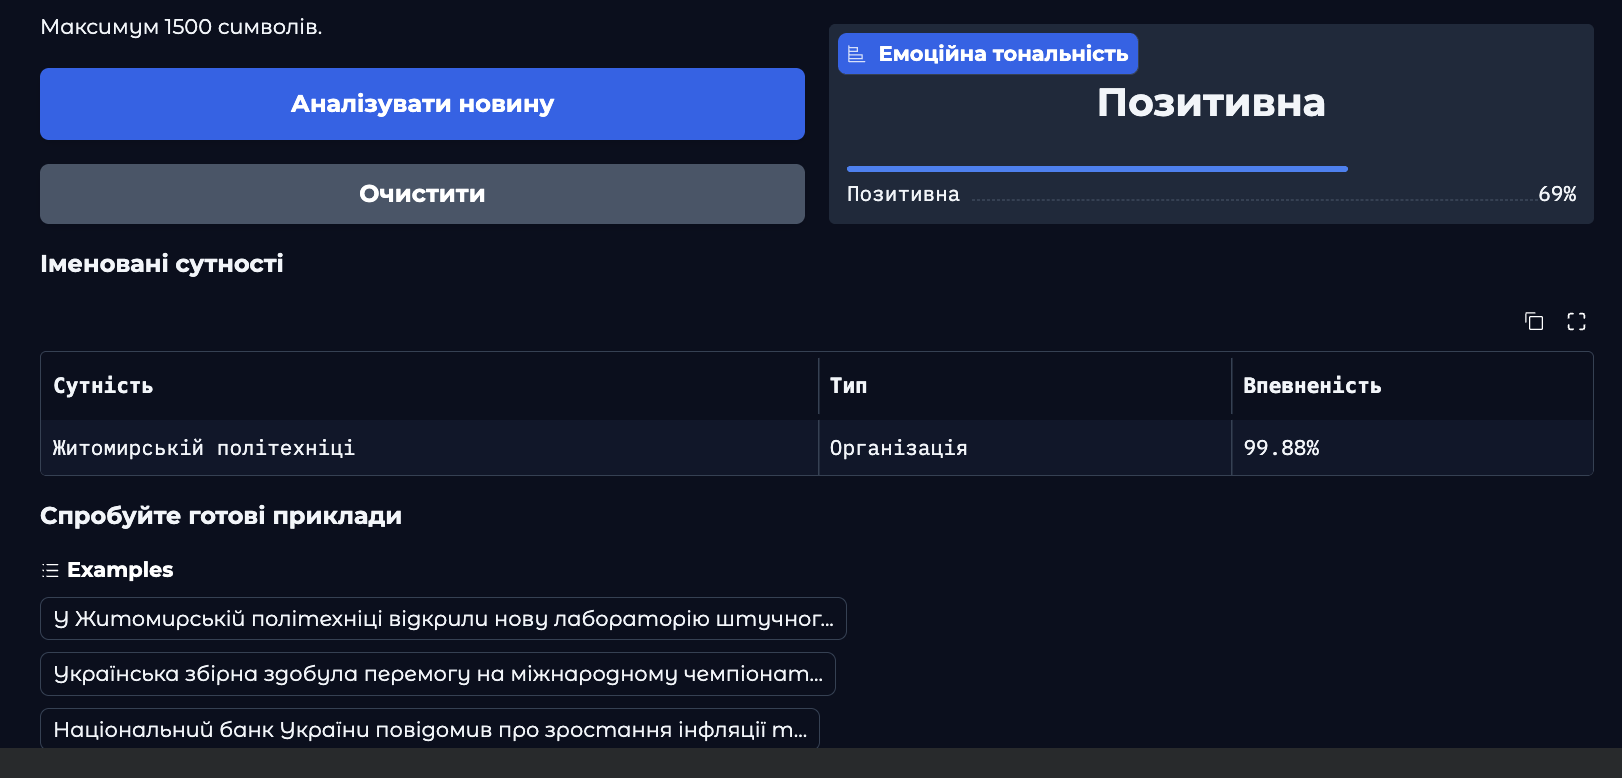

---
### Як здавати лабу

У [форму](https://forms.gle/Z1gxmsDs656jqsDGA) здати посилання на **публічний** репозиторій, який містить:

1. **Демо-ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
2. **Цей ноутбук з усіма виконаними пунктами**. Має запускатися зверху до низу (Run All) в будь-якому середовищі без помилок.
3. **Файли всіх натренованих варіантів mini-GPT** (3.2) — кожен окремим `.pt` файлом.
4. **Логи TensorBoard** — папка `runs/` з усіма прогонами (і mini-GPT, і, за бажання, логи порівняння в розділі 5).
5. **Таблицю результатів** — `results.csv` з порівнянням варіантів mini-GPT (val_loss) і моделей з розділу 5.
6. Структура файлів на репозиторії, **точно дотримуйтесь, інакше не зарахується лаба**:
```
/lab3/transformers_demo.ipynb
/lab3/transformers_task.ipynb
/lab3/models/minigpt_v1.pt
/lab3/models/minigpt_v2.pt
/lab3/models/...        (усі інші варіанти з 3.2)
/lab3/runs/*
/lab3/results.csv
```